In [ ]:
import datetime
import pandas as pd
import numpy as np
from pandas_datareader import data as wb
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure, text
import datetime

In [ ]:
import yfinance as yf
import networkx as nx

## **Indian Stock Market**

# Data Collection and Analysis

In [ ]:
data_india = yf.download("TCS.NS HDFCBANK.NS INFY.NS HINDUNILVR.NS ICICIBANK.NS SBIN.NS BAJFINANCE.NS KOTAKBANK.NS WIPRO.NS BHARTIARTL.NS ASIANPAINT.NS ITC.NS AXISBANK.NS MARUTI.NS LT.NS ULTRACEMCO.NS ADANIENT.NS JSWSTEEL.NS SUNPHARMA.NS TITAN.NS ONGC.NS TATASTEEL.NS NTPC.NS HAVELLS.NS HEROMOTOCO.NS PEL.NS AUROPHARMA.NS SAIL.NS LUPIN.NS APOLLOHOSP.NS GAIL.NS AMBUJACEM.NS MARICO.NS TATACONSUM.NS EICHERMOT.NS BERGEPAINT.NS INDUSINDBK.NS CIPLA.NS HINDALCO.NS BRITANNIA.NS GODREJCP.NS DRREDDY.NS M&M.NS GRASIM.NS VEDL.NS DABUR.NS BPCL.NS IOC.NS SHREECEM.NS PIDILITIND.NS TATAMOTORS.NS BOSCHLTD.NS BANKBARODA.NS COLPAL.NS PNB.NS IOB.NS BIOCON.NS TORNTPHARM.NS", start="2006-01-02", end="2025-01-02")

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  58 of 58 completed


In [ ]:
data_india

Price             Close                                           \
Ticker      ADANIENT.NS AMBUJACEM.NS APOLLOHOSP.NS ASIANPAINT.NS   
Date                                                               
2006-01-02     3.578927    54.791027    223.488007     48.314812   
2006-01-03     3.620751    56.034691    223.310349     48.675167   
2006-01-04     3.641662    60.629414    225.176041     48.355770   
2006-01-05     3.614775    60.560318    231.772751     48.318913   
2006-01-06     3.641662    60.387569    238.813660     48.368057   
...                 ...          ...           ...           ...   
2024-12-26  2400.250000   548.799988   7250.894531   2262.399902   
2024-12-27  2409.949951   547.950012   7236.065430   2271.399902   
2024-12-30  2592.350098   544.599976   7303.919434   2288.250000   
2024-12-31  2528.649902   535.799988   7286.044922   2281.350098   
2025-01-01  2554.850098   538.599976   7359.241211   2304.649902   

Price                                                              \
Ticker     AUROPHARMA.NS  AXISBANK.NS BAJFINANCE.NS BANKBARODA.NS   
Date                                                                
2006-01-02     35.635551    50.400818     35.085129     33.944763   
2006-01-03     36.493305    50.628086     34.761616     34.478008   
2006-01-04     37.554665    51.834347     34.640411     36.112804   
2006-01-05     37.628319    53.093056     34.386890     36.688137   
2006-01-06     37.264420    54.867493     34.211906     36.477646   
...                  ...          ...           ...           ...   
2024-12-26   1256.250000  1076.699951   6815.750000    246.679993   
2024-12-27   1269.949951  1077.449951   6907.750000    244.990005   
2024-12-30   1298.300049  1069.949951   6888.250000    241.000000   
2024-12-31   1334.500000  1064.699951   6823.000000    240.550003   
2025-01-01   1353.250000  1071.800049   6935.299805    241.220001   

Price                                   ...       Volume                \
Ticker     BERGEPAINT.NS BHARTIARTL.NS  ... SUNPHARMA.NS TATACONSUM.NS   
Date                                    ...                              
2006-01-02     11.223879    142.034943  ...       772858       1274400   
2006-01-03     11.223879    144.708099  ...      1254735        540030   
2006-01-04     11.691543    144.081543  ...      2365804        823680   
2006-01-05     11.535655    143.037369  ...      1419736        513420   
2006-01-06     11.691543    145.042267  ...      1308409        472140   
...                  ...           ...  ...          ...           ...   
2024-12-26    441.000000   1599.500000  ...      1402706        595956   
2024-12-27    442.299988   1599.849976  ...      1668898        870974   
2024-12-30    448.250000   1586.900024  ...      6021550       1830048   
2024-12-31    448.549988   1587.750000  ...      1844944       1120133   
2025-01-01    458.149994   1595.699951  ...      1338092        641424   

Price                                                                   \
Ticker     TATAMOTORS.NS TATASTEEL.NS   TCS.NS  TITAN.NS TORNTPHARM.NS   
Date                                                                     
2006-01-02       5214819     22888234  1653504  19743920        113456   
2006-01-03       4765590     24164536  3396936  15052920        257584   
2006-01-04       5389473     27038404  3545616  40563080        356352   
2006-01-05       8171570     16543852  1431824  81395780        158832   
2006-01-06      10202258     28601856  2965744  63893580         95312   
...                  ...          ...      ...       ...           ...   
2024-12-26       9343210     23939932  1208464    637094        122364   
2024-12-27      15835079     19562177   858100    568989        220832   
2024-12-30      17441198     32555723  1527169    941859       1040305   
2024-12-31       7092699     20080291  1555429    616440        153583   
2025-01-01       7792251     18169498   763161    357376        174032   

Price 

In [ ]:
data = data_india['Close']
data2 = data.dropna()
data2.shape

(4685, 58)

In [ ]:
#Logarithmic Returns
tickers = list(data2.columns)
tickers_dict = {}

for i in range(len(tickers)):
  tickers_dict[i] = tickers[i]

data3 = pd.DataFrame(columns = tickers)

for ticker in tickers:
  data3[ticker] = np.log(data2[ticker]) - np.log(data2[ticker].shift(1))

data3 = data3.dropna()
print(data3.head())

            ADANIENT.NS  AMBUJACEM.NS  APOLLOHOSP.NS  ASIANPAINT.NS  \
Date                                                                  
2006-01-03     0.011618      0.022445      -0.000795       0.007431   
2006-01-04     0.005759      0.078809       0.008320      -0.006583   
2006-01-05    -0.007411     -0.001140       0.028875      -0.000763   
2006-01-06     0.007411     -0.002857       0.029926       0.001017   
2006-01-09     0.001639     -0.011508      -0.013483      -0.004157   

            AUROPHARMA.NS  AXISBANK.NS  BAJFINANCE.NS  BANKBARODA.NS  \
Date                                                                   
2006-01-03       0.023785     0.004499      -0.009264       0.015587   
2006-01-04       0.028669     0.023547      -0.003493       0.046326   
2006-01-05       0.001959     0.023993      -0.007346       0.015806   
2006-01-06      -0.009718     0.032875      -0.005102      -0.005754   
2006-01-09       0.126400     0.018155      -0.008117      -0.006174  

In [ ]:
st = datetime.datetime(2017,1,2)
fn = datetime.datetime(2018,1,2)
msk = (data3.index >= st) & (data3.index < fn)
data41 = data3.loc[msk]
data41.head()

,ADANIENT.NS,AMBUJACEM.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AUROPHARMA.NS,AXISBANK.NS,BAJFINANCE.NS,BANKBARODA.NS,BERGEPAINT.NS,BHARTIARTL.NS,...,SUNPHARMA.NS,TATACONSUM.NS,TATAMOTORS.NS,TATASTEEL.NS,TCS.NS,TITAN.NS,TORNTPHARM.NS,ULTRACEMCO.NS,VEDL.NS,WIPRO.NS
Date,,,,,,,,,,,,,,,,,,,,,
2017-01-02,0.005212,0.039444,0.007851,0.015148,0.009221,-0.004901,0.032533,-0.029774,0.004738,0.017353,...,0.006408,0.012625,0.031388,0.038852,-0.001777,0.021643,-0.004871,0.036597,0.021964,-0.006131
2017-01-03,-0.005212,0.002792,0.013572,-0.008938,-0.004897,0.016612,0.015907,-0.002017,0.008941,-0.021286,...,0.003228,0.007258,-0.012292,-0.008518,0.002918,0.041642,0.021659,-0.013333,-0.005901,-0.009696
2017-01-04,0.016197,-0.014274,0.012776,0.011091,-0.007841,-0.004734,-0.013782,-0.004046,0.005606,0.030568,...,0.001963,0.000000,0.011470,0.005317,0.004739,0.032498,0.007586,-0.007634,-0.013060,0.018248
2017-01-05,0.017203,0.010317,-0.011284,0.010861,0.028527,0.010865,0.031442,0.019736,-0.003266,0.022678,...,0.009525,0.006009,0.031354,0.033589,-0.019136,-0.004459,0.005873,0.024372,0.048834,0.010042
2017-01-06,-0.006337,-0.008198,-0.008945,0.014085,0.008922,-0.006241,-0.023958,0.015122,0.025382,-0.004213,...,-0.004205,-0.004403,-0.008801,0.000596,-0.022965,-0.007992,0.013390,-0.017926,0.012875,-0.021993


In [ ]:
#Correlation Matrix
corr_matrix = data3.corr()
print(corr_matrix)
corr_matrix = corr_matrix.to_numpy()
np.fill_diagonal(corr_matrix, 0)
corr_matrix

               ADANIENT.NS  AMBUJACEM.NS  APOLLOHOSP.NS  ASIANPAINT.NS  \
ADANIENT.NS       1.000000      0.358779       0.200741       0.211941   
AMBUJACEM.NS      0.358779      1.000000       0.211387       0.260281   
APOLLOHOSP.NS     0.200741      0.211387       1.000000       0.197654   
ASIANPAINT.NS     0.211941      0.260281       0.197654       1.000000   
AUROPHARMA.NS     0.255382      0.243136       0.195568       0.187533   
AXISBANK.NS       0.322869      0.359175       0.245467       0.252994   
BAJFINANCE.NS     0.254929      0.264205       0.211355       0.245718   
BANKBARODA.NS     0.358966      0.348765       0.197190       0.209589   
BERGEPAINT.NS     0.219181      0.241165       0.182047       0.350698   
BHARTIARTL.NS     0.241785      0.300309       0.160628       0.202165   
BIOCON.NS         0.243413      0.242532       0.194707       0.189486   
BOSCHLTD.NS       0.222855      0.238733       0.181947       0.225997   
BPCL.NS           0.247951      0.2961

array([[0.        , 0.35877861, 0.20074124, ..., 0.28919249, 0.32535041,
        0.20615856],
       [0.35877861, 0.        , 0.21138703, ..., 0.52699207, 0.32677647,
        0.29266664],
       [0.20074124, 0.21138703, 0.        , ..., 0.21623837, 0.22197919,
        0.19091386],
       ...,
       [0.28919249, 0.52699207, 0.21623837, ..., 0.        , 0.33071543,
        0.27025494],
       [0.32535041, 0.32677647, 0.22197919, ..., 0.33071543, 0.        ,
        0.27603839],
       [0.20615856, 0.29266664, 0.19091386, ..., 0.27025494, 0.27603839,
        0.        ]])

In [ ]:
#Constructing Threshold Network
adjacency_matrix = corr_matrix.copy()
threshold = 0.36
adjacency_matrix[adjacency_matrix >= threshold] = 1
adjacency_matrix[adjacency_matrix < threshold] = 0
adjacency_matrix

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

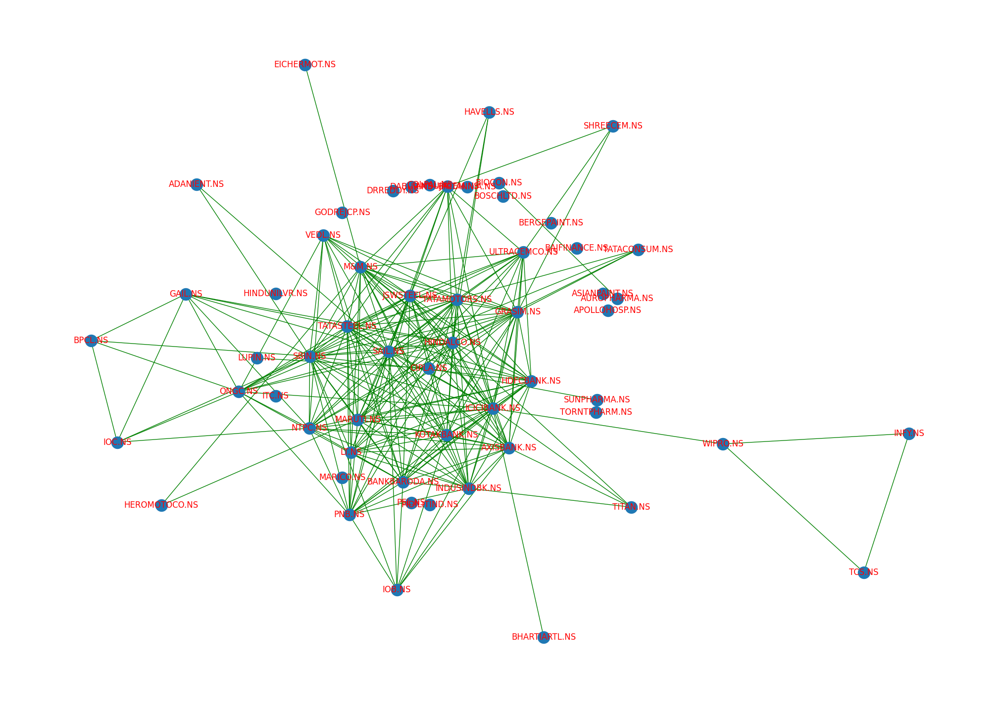

In [ ]:
network_graph = nx.from_numpy_array(np.array(adjacency_matrix))
f = plt.figure(figsize=(20,14))

nx.draw_kamada_kawai(network_graph, with_labels=True,labels = tickers_dict, font_color='r',edge_color='g')

In [ ]:
#Average correlation
avg_corr = np.mean(corr_matrix)
avg_corr

np.float64(0.2680079084675257)

In [ ]:
avg_clustering = nx.average_clustering(network_graph)
avg_clustering

0.5014151000775761

In [ ]:
Gcc = sorted(nx.connected_components(network_graph), key=len, reverse=True)
G0 = network_graph.subgraph(Gcc[0])
avg_length = nx.average_shortest_path_length(G0)
avg_length

1.864864864864865

In [ ]:
#Degree Centrality
degree_centrality = nx.degree_centrality(network_graph)

#Betweenness Centrality
betweenness = nx.betweenness_centrality(network_graph, normalized = True, endpoints = False)
# betweenness

#Closeness Centrality
closeness = nx.closeness_centrality(network_graph)
#closeness

#PageRank
page_rank = nx.pagerank(network_graph, alpha = 0.8)
#pagerank

#EigenVector
eigen_vector = nx.eigenvector_centrality(network_graph)
# eigen

In [ ]:
eigen_sort = sorted(eigen_vector.items(), key=lambda x: x[1], reverse=True)
betweenness_sort = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)
closeness_sort = sorted(closeness.items(), key=lambda x: x[1], reverse=True)
pagerank_sort = sorted(page_rank.items(), key=lambda x: x[1], reverse=True)
degree_sort = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)

list_eigen = []
list_betweenness = []
list_closeness = []
list_pagerank = []
list_degree = []

for tuple in eigen_sort:
  list_eigen.append(tuple[0])
for tuple in betweenness_sort:
  list_betweenness.append(tuple[0])
for tuple in closeness_sort:
  list_closeness.append(tuple[0])
for tuple in pagerank_sort:
  list_pagerank.append(tuple[0])
for tuple in degree_sort:
  list_degree.append(tuple[0])

dict_rank = {}

for i in range(58):
  dict_rank[i] = ((list_eigen.index(i) + list_betweenness.index(i) + list_closeness.index(i) + list_degree.index(i) + list_pagerank.index(i)) / 5) + 1

dict_rank

{0: 32.0,
 1: 20.8,
 2: 40.0,
 3: 41.0,
 4: 34.2,
 5: 10.4,
 6: 42.2,
 7: 13.0,
 8: 43.2,
 9: 35.6,
 10: 36.0,
 11: 44.6,
 12: 31.0,
 13: 45.8,
 14: 28.2,
 15: 46.8,
 16: 47.8,
 17: 48.8,
 18: 38.4,
 19: 24.0,
 20: 50.0,
 21: 8.0,
 22: 33.8,
 23: 15.4,
 24: 36.6,
 25: 3.4,
 26: 51.4,
 27: 2.0,
 28: 12.4,
 29: 36.6,
 30: 29.8,
 31: 27.8,
 32: 52.8,
 33: 7.0,
 34: 13.0,
 35: 19.6,
 36: 39.0,
 37: 11.8,
 38: 54.0,
 39: 14.4,
 40: 14.6,
 41: 18.4,
 42: 55.0,
 43: 56.0,
 44: 17.6,
 45: 3.8,
 46: 1.6,
 47: 36.4,
 48: 40.8,
 49: 33.8,
 50: 5.6,
 51: 8.2,
 52: 39.4,
 53: 34.2,
 54: 58.0,
 55: 17.8,
 56: 23.4,
 57: 23.8}

In [ ]:
# influential_stocks

influential_stocks = sorted(dict_rank.items(), key=lambda x: x[1], reverse=False)

for i in range(20):
 print(tickers_dict[influential_stocks[i][0]])

SBIN.NS
ICICIBANK.NS
HINDALCO.NS
SAIL.NS
TATAMOTORS.NS
JSWSTEEL.NS
GRASIM.NS
TATASTEEL.NS
AXISBANK.NS
M&M.NS
INDUSINDBK.NS
BANKBARODA.NS
KOTAKBANK.NS
MARUTI.NS
NTPC.NS
HDFCBANK.NS
PNB.NS
ULTRACEMCO.NS
ONGC.NS
LT.NS


In [ ]:
#Array of Dates
dates = []
time_period = 19
start = datetime.datetime(2006, 1, 2)
for i in range(time_period+1):
  temp = datetime.datetime(start.year+i, 1, 2)
  dates.append(temp)
# dates

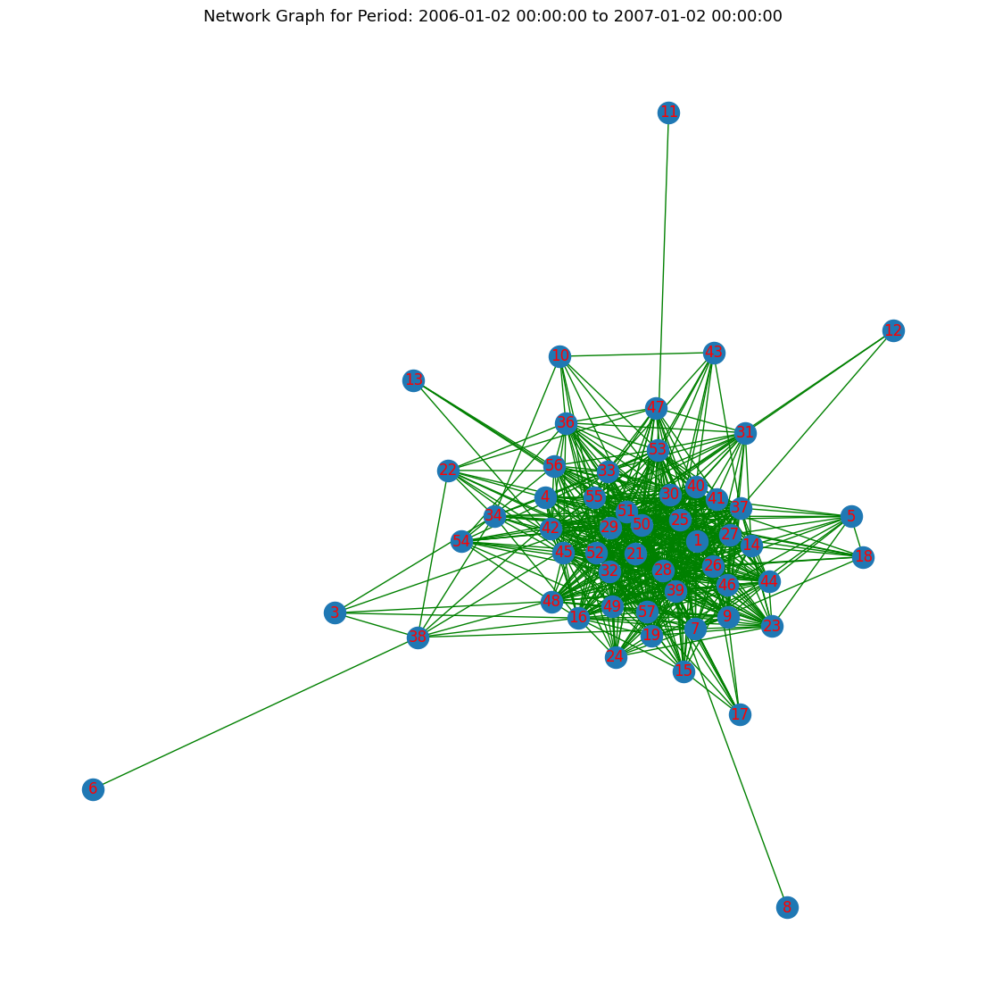

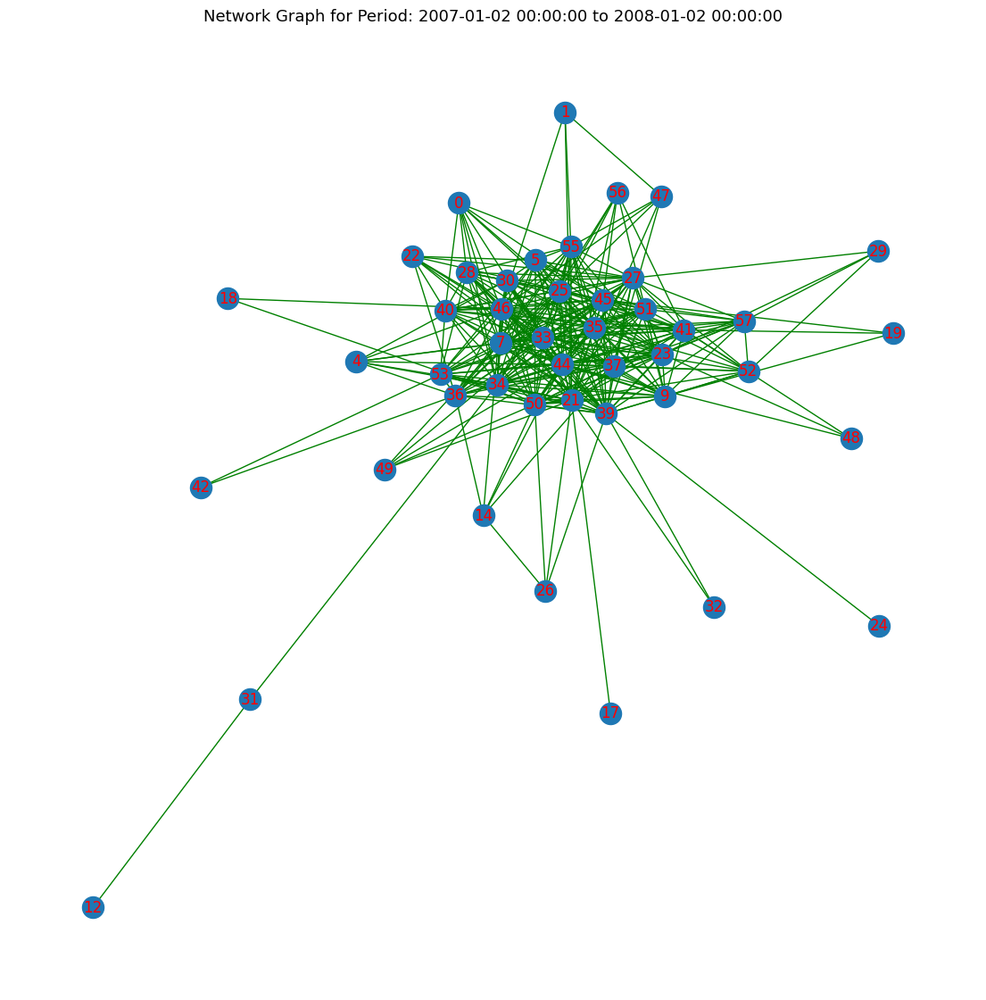

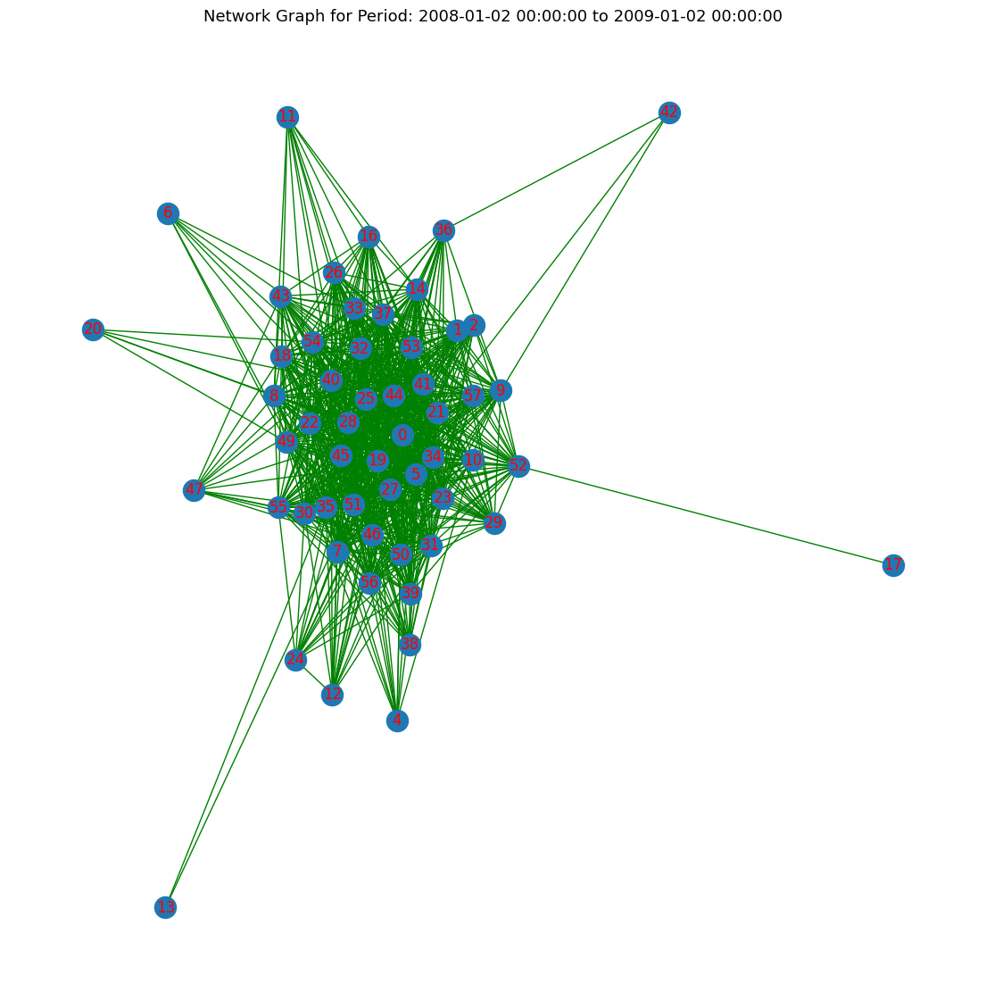

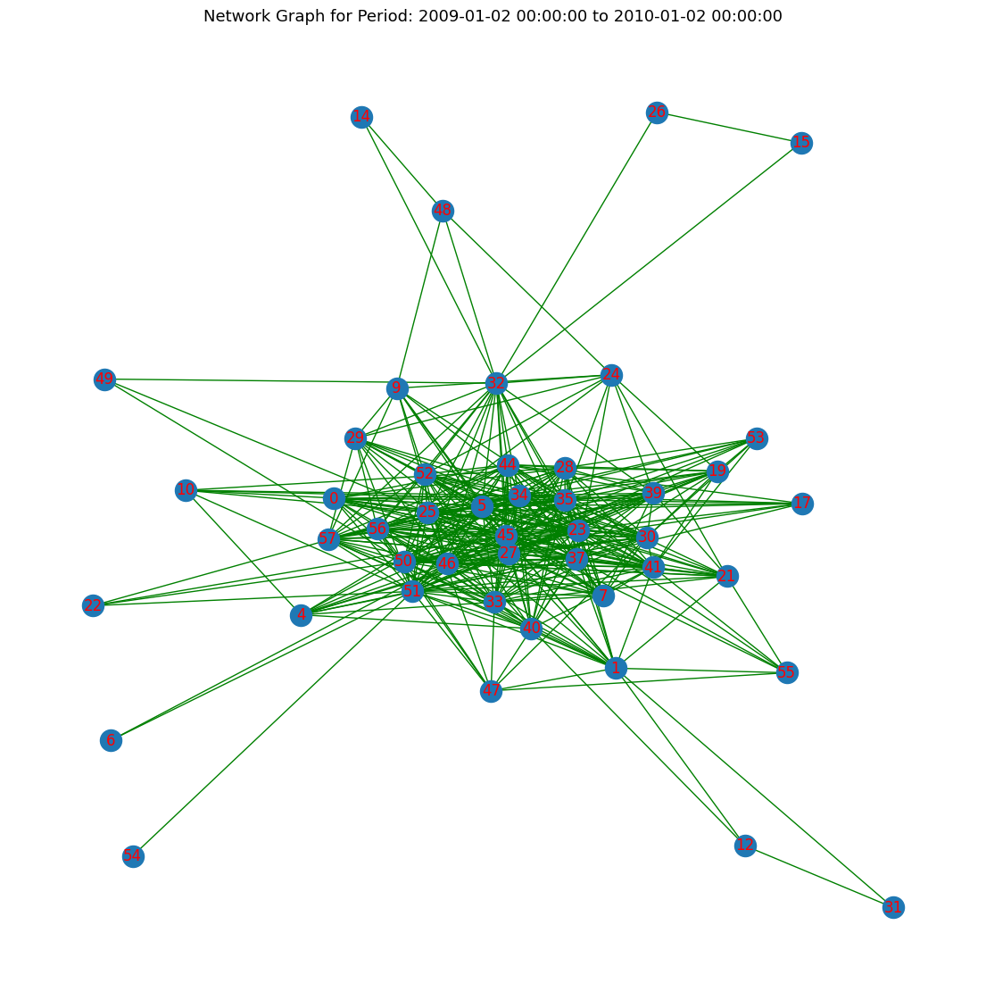

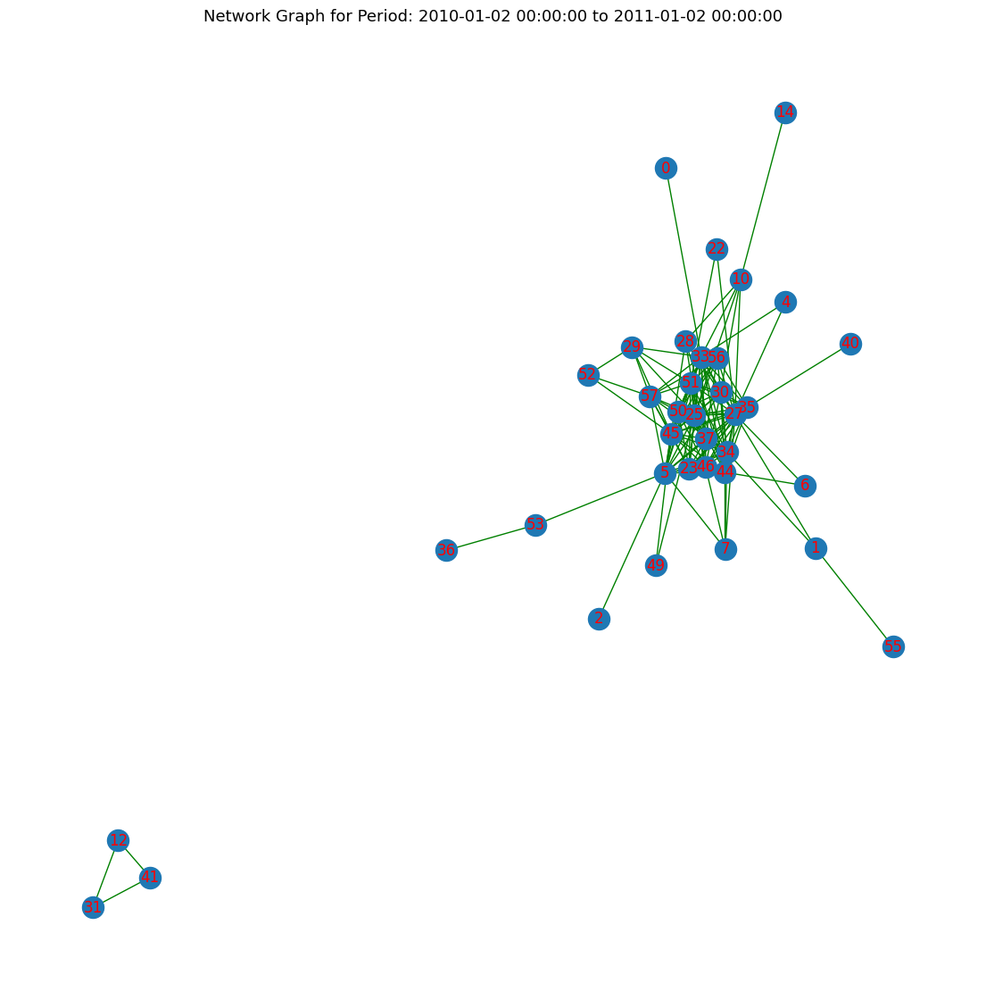

...

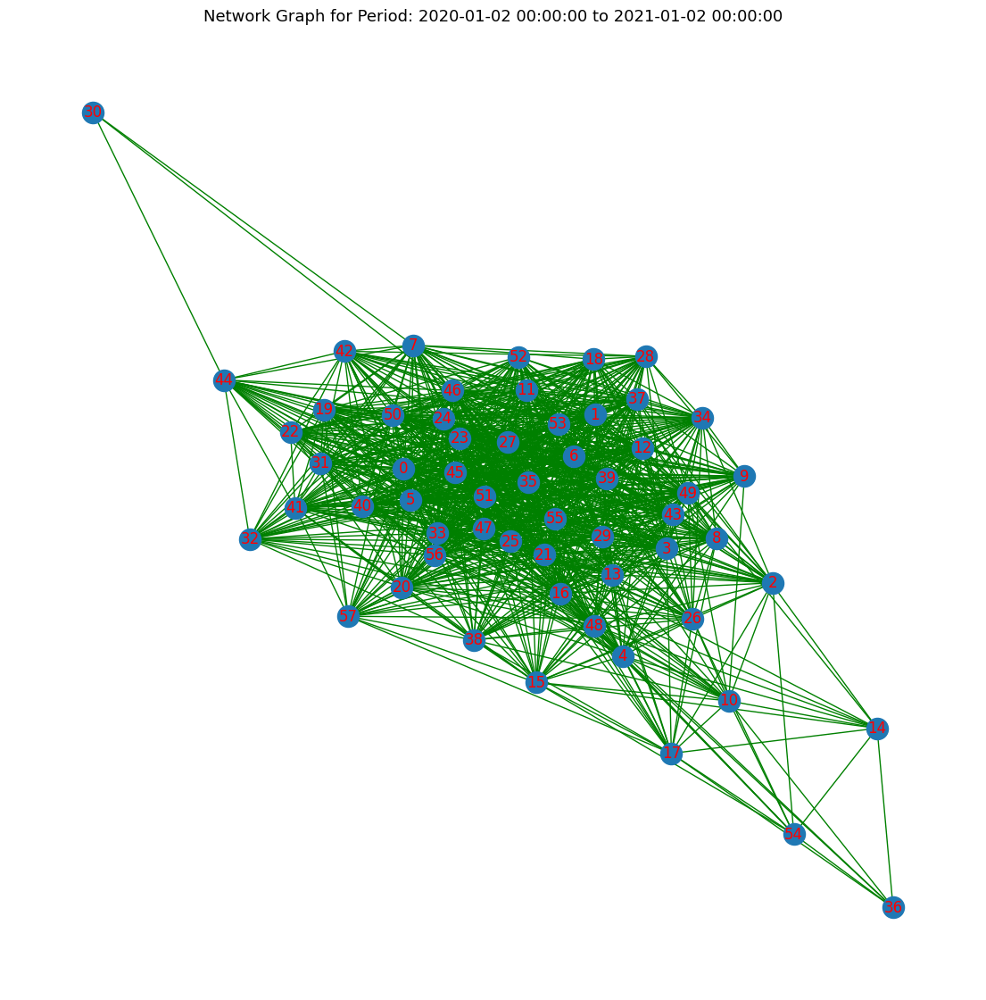

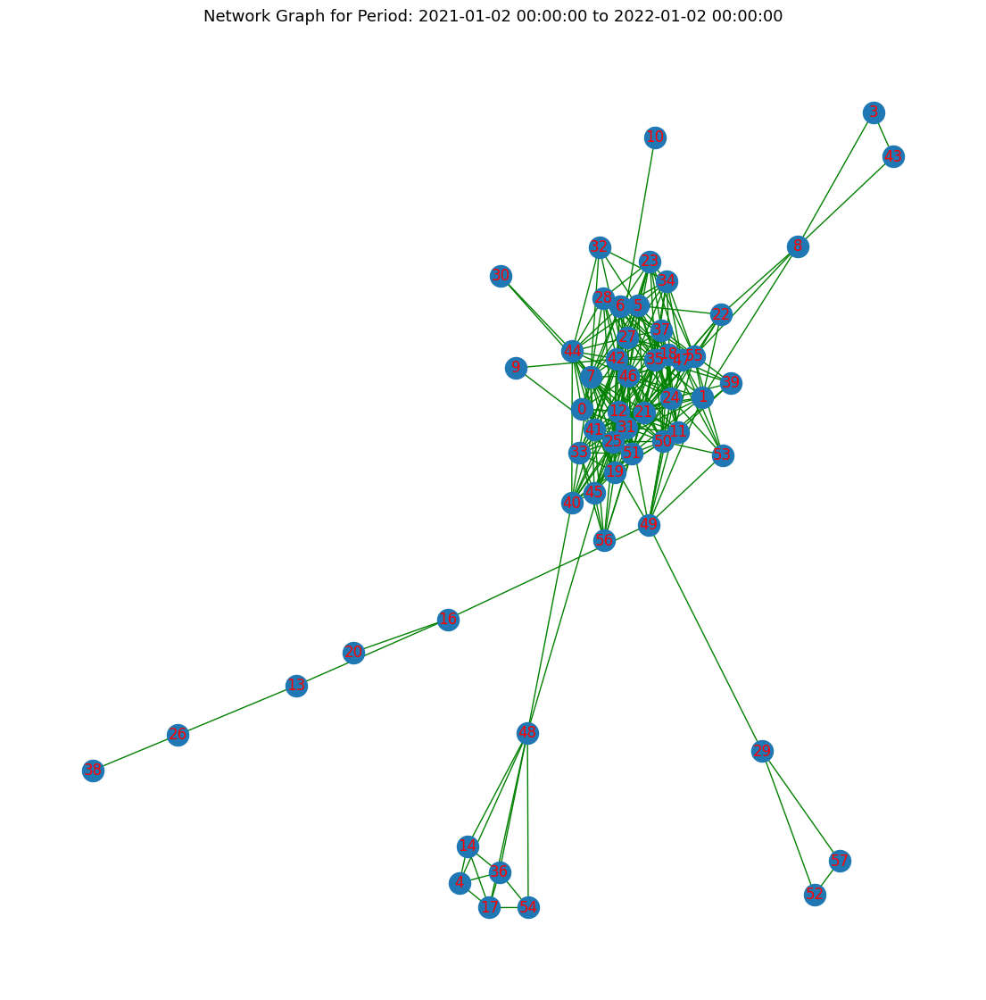

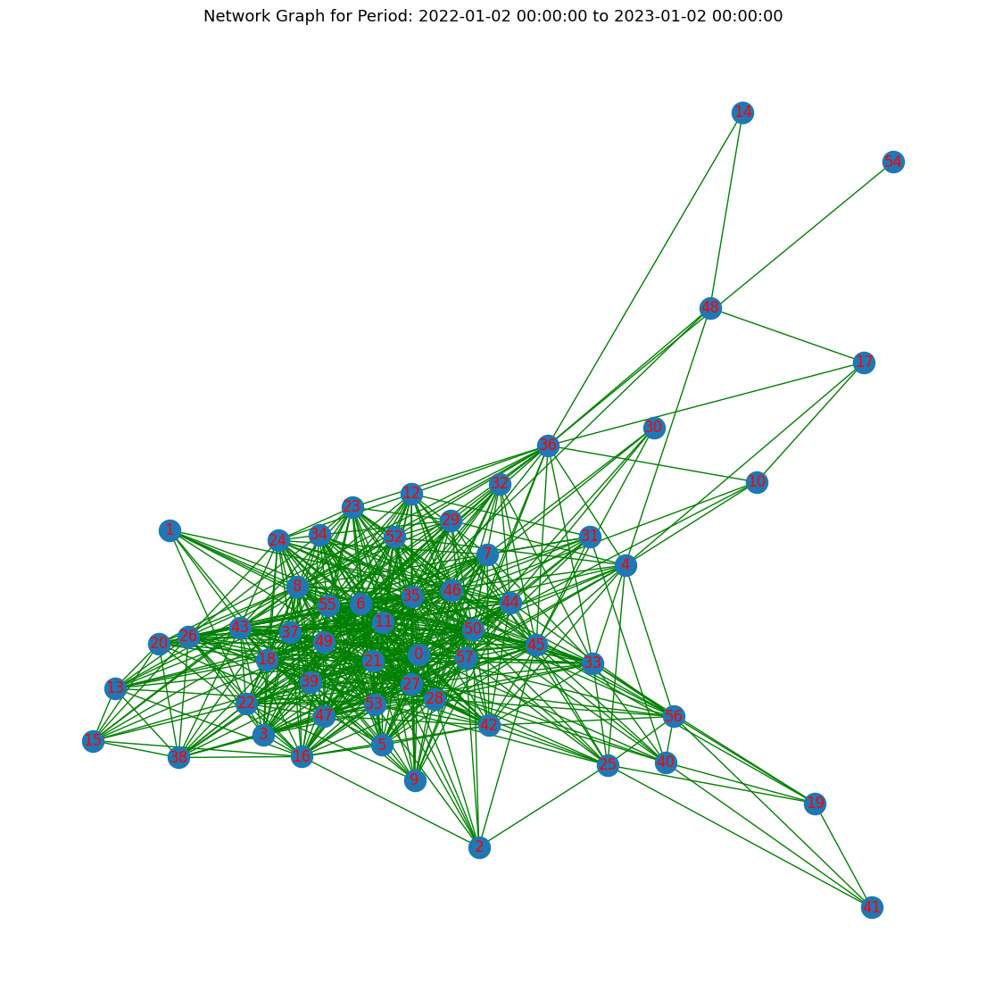

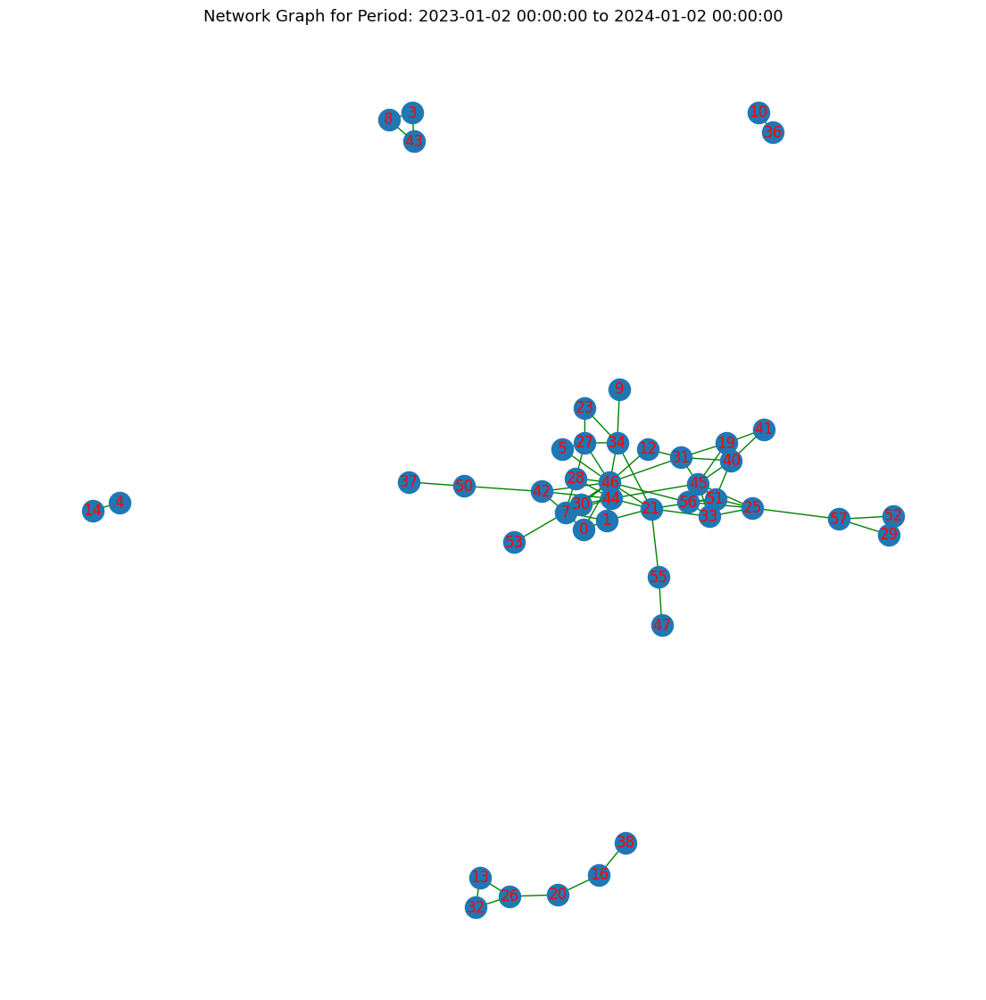

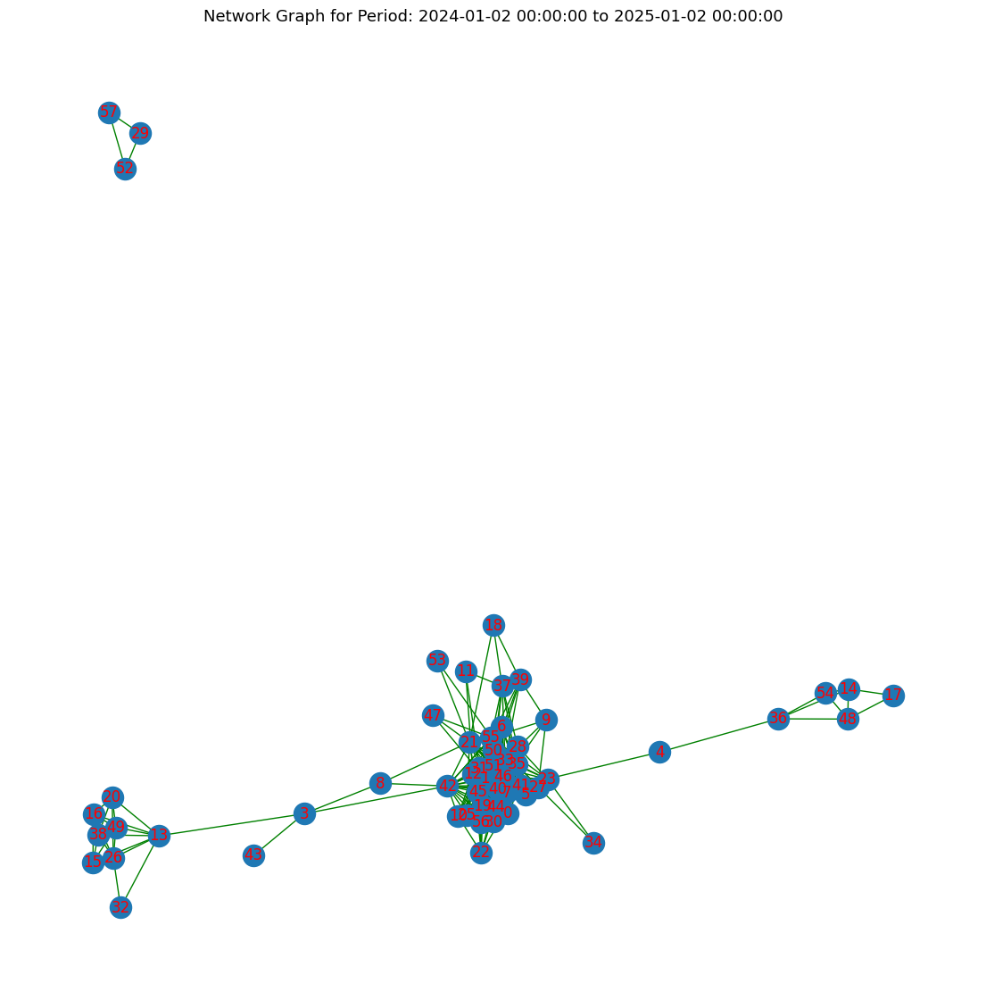

In [ ]:
# for i in range(time_period):
list_corr = []
list_density = []
list_cluster = []
list_path = []

for i in range(time_period):
  mask = (data3.index >= dates[i]) & (data3.index < dates[i+1])
  period_data = data3.loc[mask]

  corr_period_matrix = period_data.corr()
  corr_period_matrix = corr_period_matrix.to_numpy()
  np.fill_diagonal(corr_period_matrix, 0)

  adjacency_matrix_pr = corr_period_matrix.copy()
  adjacency_matrix_pr[adjacency_matrix_pr >= threshold] = 1
  adjacency_matrix_pr[adjacency_matrix_pr < threshold] = 0

  network_graph_temp = nx.from_numpy_array(np.array(adjacency_matrix_pr))
  f = plt.figure(figsize=(14, 14))
  plt.title(f"Network Graph for Period: {dates[i]} to {dates[i+1]}", fontsize=13)
  network_graph_temp.remove_nodes_from(list(nx.isolates(network_graph_temp)))
  nx.draw_spring(network_graph_temp, with_labels=True,font_color='r',edge_color='g')

  avg_corr_pr = np.mean(corr_period_matrix)
  ntwk_density_pr = nx.density(network_graph_temp)
  list_corr.append(avg_corr_pr)
  list_density.append(ntwk_density_pr)

  avg_clustering_pr = nx.average_clustering(network_graph_temp)
  list_cluster.append(avg_clustering_pr)

  Gcc_temp = sorted(nx.connected_components(network_graph_temp), key=len, reverse=True)
  G0_temp = network_graph_temp.subgraph(Gcc_temp[0])
  avg_length_pr = nx.average_shortest_path_length(G0_temp)
  list_path.append(avg_length_pr)

##**US Stock Market**

In [ ]:
data_US = yf.download("AAPL MSFT AMZN GOOG BRK-B NVDA JPM JNJ WMT UNH BAC HD PG DIS ASML ADBE XOM CMCSA NKE TM NFLX QCOM SAP MDT BHP MS MCD COST TXN UPS WFC ACN NVO DHR MRK TMO PEP CVX NVS ABT T PFE LLY ORCL CSCO CRM INTC KO AZN HON UL LIN BMY UNP C NEE AMGN BA LOW", start="2006-01-02", end="2025-01-02")

[*********************100%***********************]  59 of 59 completed


In [ ]:
data1_US = data_US['Close']
data2_US = data1_US.dropna()
data2_US.shape

(4781, 59)

In [ ]:
#Logarithmic Returns
tickers_US = list(data2_US.columns)
tickers_dict_US = {}

for i in range(len(tickers_US)):
  tickers_dict_US[i] = tickers_US[i]

data3_US = pd.DataFrame(columns = tickers_US)

for ticker in tickers_US:
  data3_US[ticker] = np.log(data2_US[ticker]) - np.log(data2_US[ticker].shift(1))

data3_US = data3_US.dropna()
print(data3_US.head())

                AAPL       ABT       ACN      ADBE      AMGN      AMZN  \
Date                                                                     
2006-01-04  0.002939  0.001516  0.005446 -0.002599 -0.004740 -0.006960   
2006-01-05 -0.007901  0.012794  0.007440 -0.009152 -0.014610  0.008430   
2006-01-06  0.025486  0.019011  0.048341  0.024135 -0.009177  0.004606   
2006-01-09 -0.003282  0.036499 -0.002893 -0.016025  0.011205 -0.016641   
2006-01-10  0.061329 -0.009715 -0.021808  0.005975 -0.012743 -0.030845   

                ASML       AZN        BA       BAC  ...        TM       TMO  \
Date                                                ...                       
2006-01-04  0.016008  0.018320  0.010310 -0.010677  ... -0.002436  0.007567   
2006-01-05  0.021895 -0.008823 -0.011872  0.001288  ... -0.004797 -0.002625   
2006-01-06  0.032881  0.014080 -0.014033 -0.001502  ...  0.011249  0.000328   
2006-01-09  0.024748 -0.007798 -0.008398  0.000644  ...  0.008539  0.022093   
2006-01

In [ ]:
#Correlation Matrix
corr_matrix_US = data3_US.corr()
print(corr_matrix_US)
corr_matrix_US = corr_matrix_US.to_numpy()
np.fill_diagonal(corr_matrix_US, 0)
corr_matrix_US

           AAPL       ABT       ACN      ADBE      AMGN      AMZN      ASML  \
AAPL   1.000000  0.345827  0.438573  0.488555  0.342672  0.477852  0.477850   
ABT    0.345827  1.000000  0.457320  0.402565  0.461686  0.308940  0.357339   
ACN    0.438573  0.457320  1.000000  0.514517  0.382411  0.431589  0.489094   
ADBE   0.488555  0.402565  0.514517  1.000000  0.363079  0.498947  0.518770   
AMGN   0.342672  0.461686  0.382411  0.363079  1.000000  0.314827  0.337554   
AMZN   0.477852  0.308940  0.431589  0.498947  0.314827  1.000000  0.436928   
ASML   0.477850  0.357339  0.489094  0.518770  0.337554  0.436928  1.000000   
AZN    0.308627  0.413544  0.360756  0.333947  0.386477  0.267431  0.345823   
BA     0.386066  0.347959  0.437812  0.389003  0.291152  0.335809  0.432766   
BAC    0.375975  0.342004  0.415202  0.396778  0.304810  0.321707  0.385275   
BHP    0.416494  0.332831  0.463154  0.426902  0.338959  0.367119  0.505297   
BMY    0.284337  0.426720  0.354870  0.296153  0.424

array([[0.        , 0.34582677, 0.4385733 , ..., 0.35527033, 0.30431745,
        0.34509881],
       [0.34582677, 0.        , 0.45732013, ..., 0.34181919, 0.36505316,
        0.34790196],
       [0.4385733 , 0.45732013, 0.        , ..., 0.41232987, 0.33265189,
        0.4228768 ],
       ...,
       [0.35527033, 0.34181919, 0.41232987, ..., 0.        , 0.28087619,
        0.47271211],
       [0.30431745, 0.36505316, 0.33265189, ..., 0.28087619, 0.        ,
        0.30595099],
       [0.34509881, 0.34790196, 0.4228768 , ..., 0.47271211, 0.30595099,
        0.        ]])

In [ ]:
avg_corr_us = np.mean(corr_matrix_US)
avg_corr_us

np.float64(0.4011184472200137)

In [ ]:
#Constructing Threshold Network
adjacency_matrix_US = corr_matrix_US.copy()
threshold_US = 0.36
adjacency_matrix_US[adjacency_matrix_US >= threshold_US] = 1
adjacency_matrix_US[adjacency_matrix_US < threshold_US] = 0
adjacency_matrix_US

array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 1., 0.],
       [1., 1., 0., ..., 1., 0., 1.],
       ...,
       [0., 0., 1., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 1., 0., 0.]])

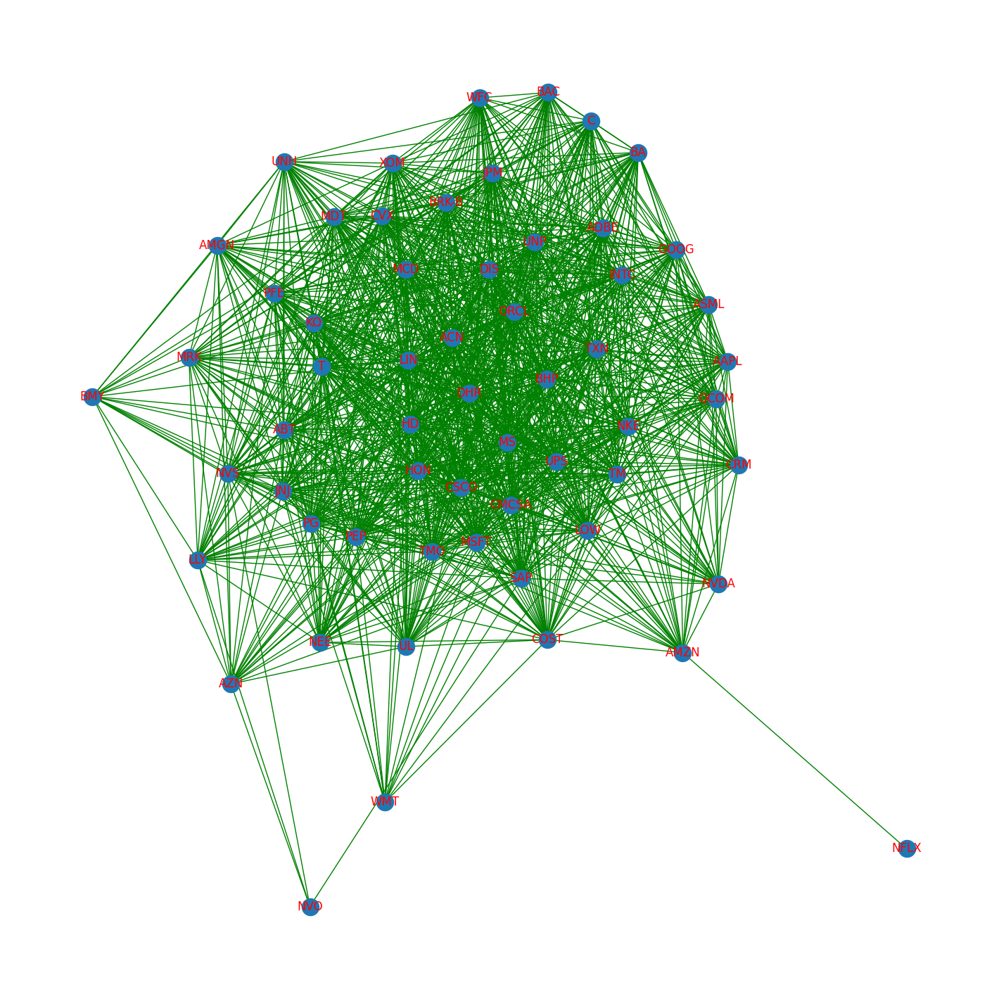

In [ ]:
# Set overall figure size
#G = nx.from_pandas_adjacency(adjacency_matrix)
network_graph_US = nx.from_numpy_array(np.array(adjacency_matrix_US))
f = plt.figure(figsize=(14, 14))

# Uses the Kamada-Kawai layout, which optimally positions nodes to reduce edge crossings.
nx.draw_kamada_kawai(network_graph_US, with_labels=True,labels = tickers_dict_US, font_color='r',edge_color='g')

In [ ]:
#Average correlation
avg_corr_US = np.mean(corr_matrix_US)
avg_corr_US

np.float64(0.4011184472200137)

In [ ]:
avg_clustering_US = nx.average_clustering(network_graph_US)
avg_clustering_US

0.8579589736067634

In [ ]:
Gcc_US = sorted(nx.connected_components(network_graph_US), key=len, reverse=True)
G0_US = network_graph_US.subgraph(Gcc_US[0])
avg_length_US = nx.average_shortest_path_length(G0_US)
avg_length_US

1.2910578609000585

In [ ]:
#Degree Centrality
degree_centrality_US = nx.degree_centrality(network_graph_US)

#Betweenness Centrality
betweenness_US = nx.betweenness_centrality(network_graph_US, normalized = True, endpoints = False)
# betweenness

#Closeness Centrality
closeness_US = nx.closeness_centrality(network_graph_US)
#closeness

#PageRank
page_rank_US = nx.pagerank(network_graph_US, alpha = 0.8)
#pagerank

#EigenVector
eigen_vector_US = nx.eigenvector_centrality(network_graph_US)
# eigen

In [ ]:
eigen_sort_US = sorted(eigen_vector_US.items(), key=lambda x: x[1], reverse=True)
betweenness_sort_US = sorted(betweenness_US.items(), key=lambda x: x[1], reverse=True)
closeness_sort_US = sorted(closeness_US.items(), key=lambda x: x[1], reverse=True)
pagerank_sort_US = sorted(page_rank_US.items(), key=lambda x: x[1], reverse=True)
degree_sort_US = sorted(degree_centrality_US.items(), key=lambda x: x[1], reverse=True)

list_eigen_US = []
list_betweenness_US = []
list_closeness_US = []
list_pagerank_US = []
list_degree_US = []

for tuple in eigen_sort_US:
  list_eigen_US.append(tuple[0])
for tuple in betweenness_sort_US:
  list_betweenness_US.append(tuple[0])
for tuple in closeness_sort_US:
  list_closeness_US.append(tuple[0])
for tuple in pagerank_sort_US:
  list_pagerank_US.append(tuple[0])
for tuple in degree_sort_US:
  list_degree_US.append(tuple[0])

dict_rank_US= {}

for i in range(59):
  dict_rank_US[i] = ((list_eigen_US.index(i) + list_betweenness_US.index(i) + list_closeness_US.index(i) + list_degree_US.index(i) + list_pagerank_US.index(i)) / 5) + 1

dict_rank_US

{0: 45.2,
 1: 33.6,
 2: 7.2,
 3: 33.0,
 4: 49.8,
 5: 41.2,
 6: 40.4,
 7: 50.4,
 8: 45.0,
 9: 45.2,
 10: 16.2,
 11: 55.8,
 12: 19.0,
 13: 41.4,
 14: 7.6,
 15: 33.0,
 16: 49.8,
 17: 3.8,
 18: 17.6,
 19: 8.6,
 20: 12.8,
 21: 38.2,
 22: 1.4,
 23: 2.4,
 24: 30.8,
 25: 32.0,
 26: 26.8,
 27: 26.8,
 28: 4.2,
 29: 45.0,
 30: 19.2,
 31: 18.4,
 32: 25.0,
 33: 48.4,
 34: 10.2,
 35: 5.2,
 36: 50.4,
 37: 58.6,
 38: 25.8,
 39: 54.0,
 40: 58.0,
 41: 34.4,
 42: 12.6,
 43: 23.8,
 44: 33.2,
 45: 29.2,
 46: 46.2,
 47: 10.2,
 48: 31.2,
 49: 26.4,
 50: 10.0,
 51: 22.2,
 52: 41.2,
 53: 46.0,
 54: 22.8,
 55: 13.4,
 56: 42.8,
 57: 57.4,
 58: 29.6}

In [ ]:
# influential_stocks

influential_stocks_US = sorted(dict_rank_US.items(), key=lambda x: x[1], reverse=False)

for i in range(20):
 print(tickers_dict_US[influential_stocks_US[i][0]])

HD
HON
CSCO
LIN
MSFT
ACN
CMCSA
DHR
TMO
MS
SAP
ORCL
DIS
UPS
BHP
CVX
MCD
BRK-B
LOW
TXN


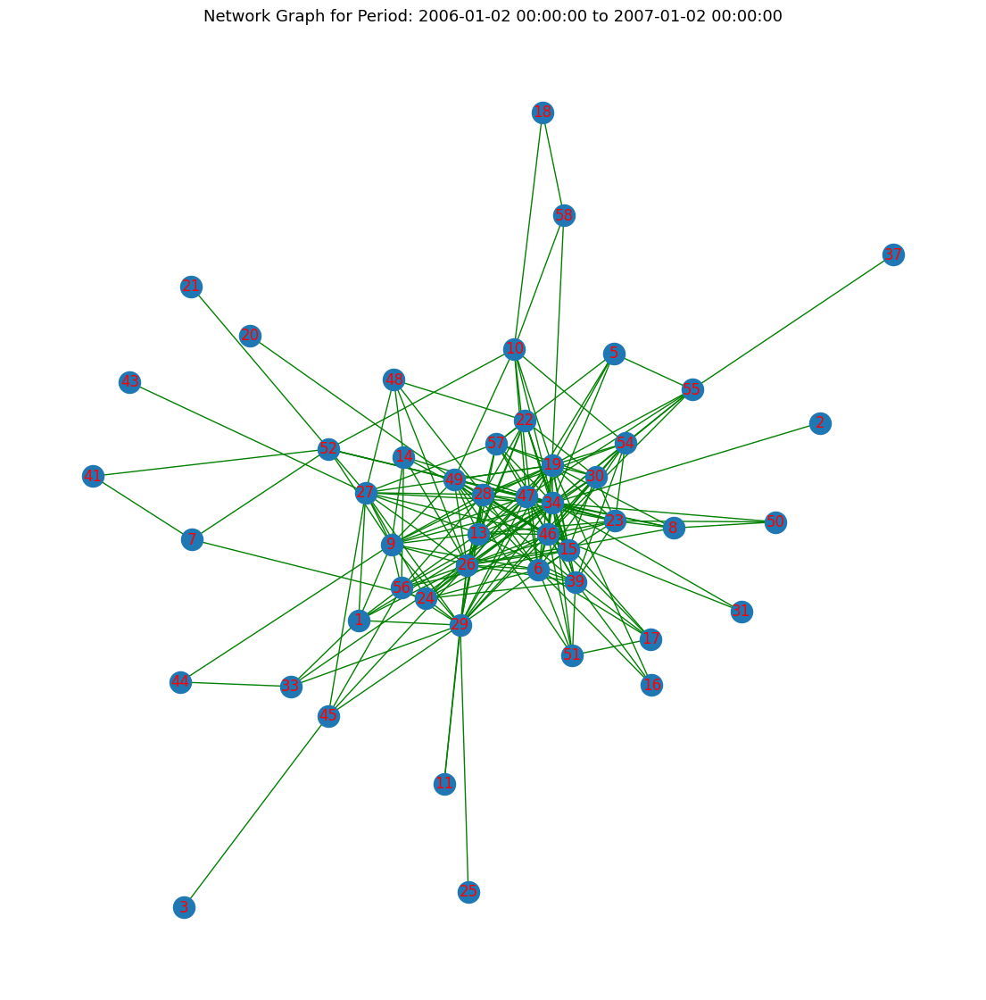

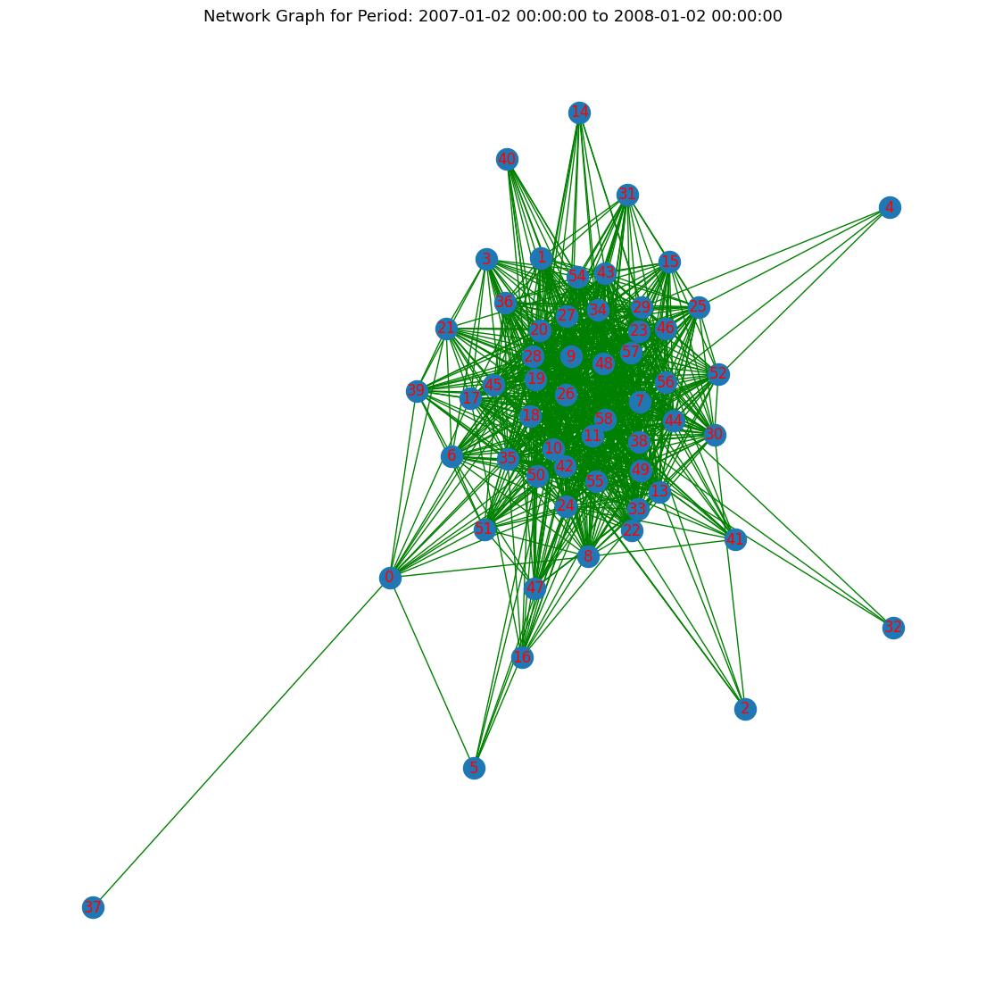

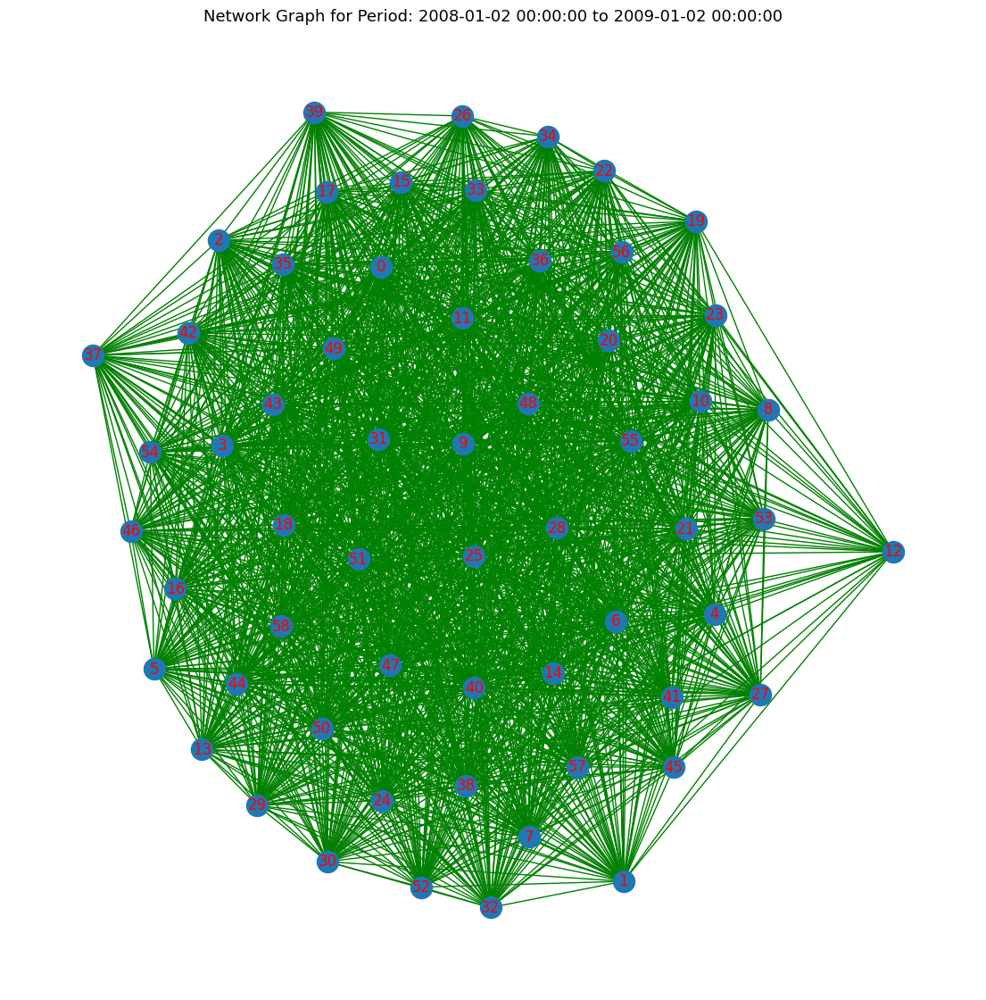

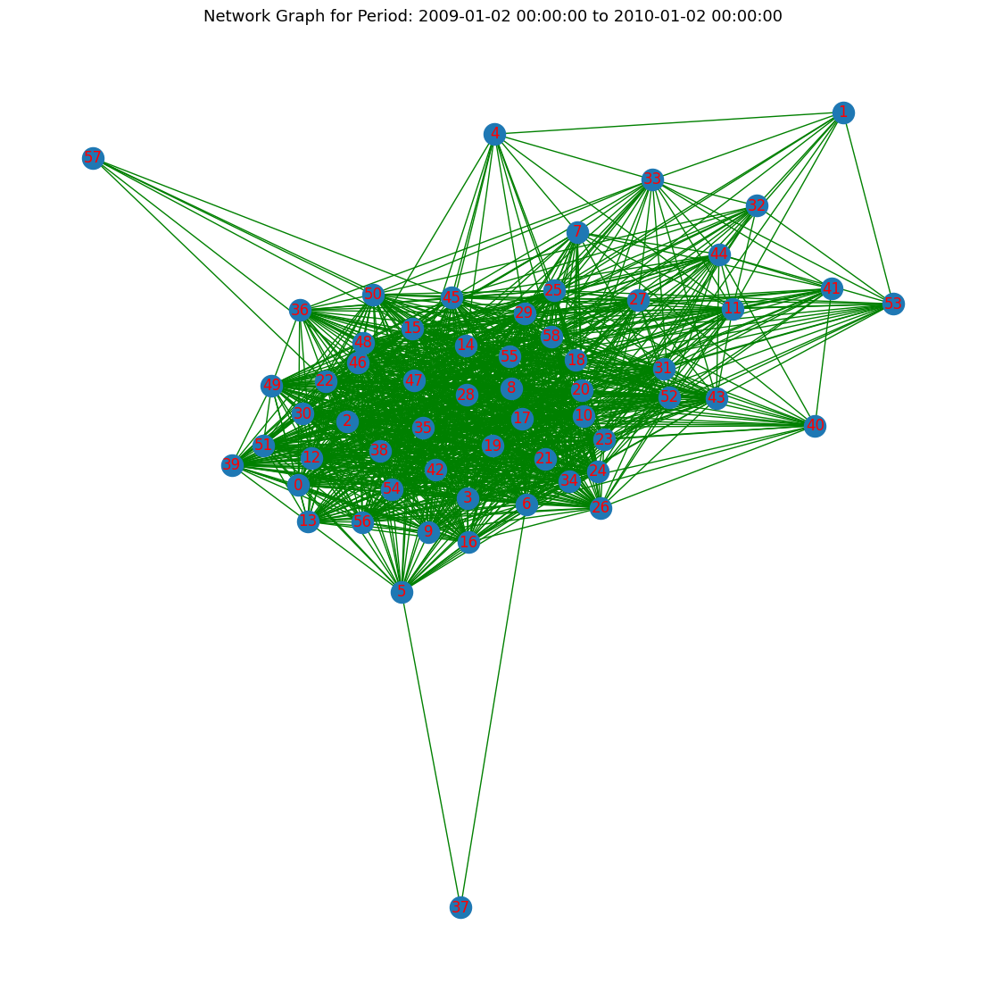

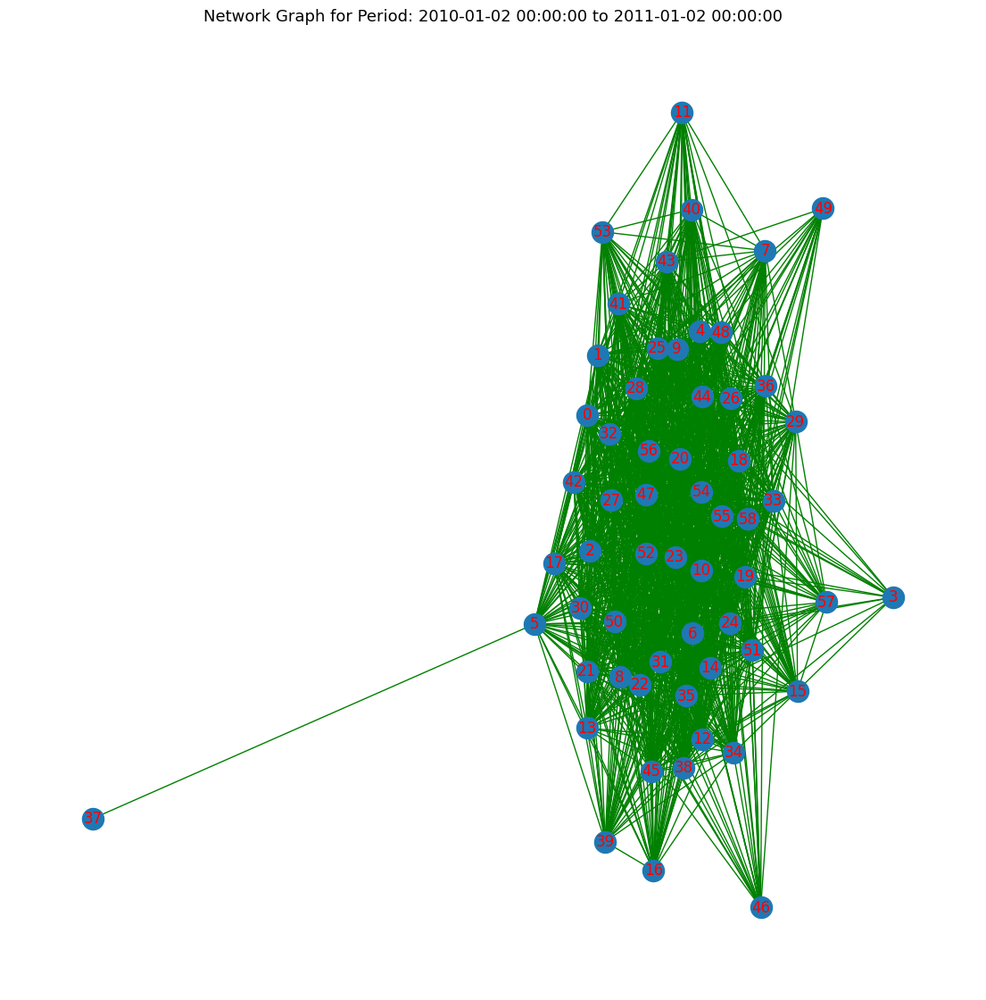

...

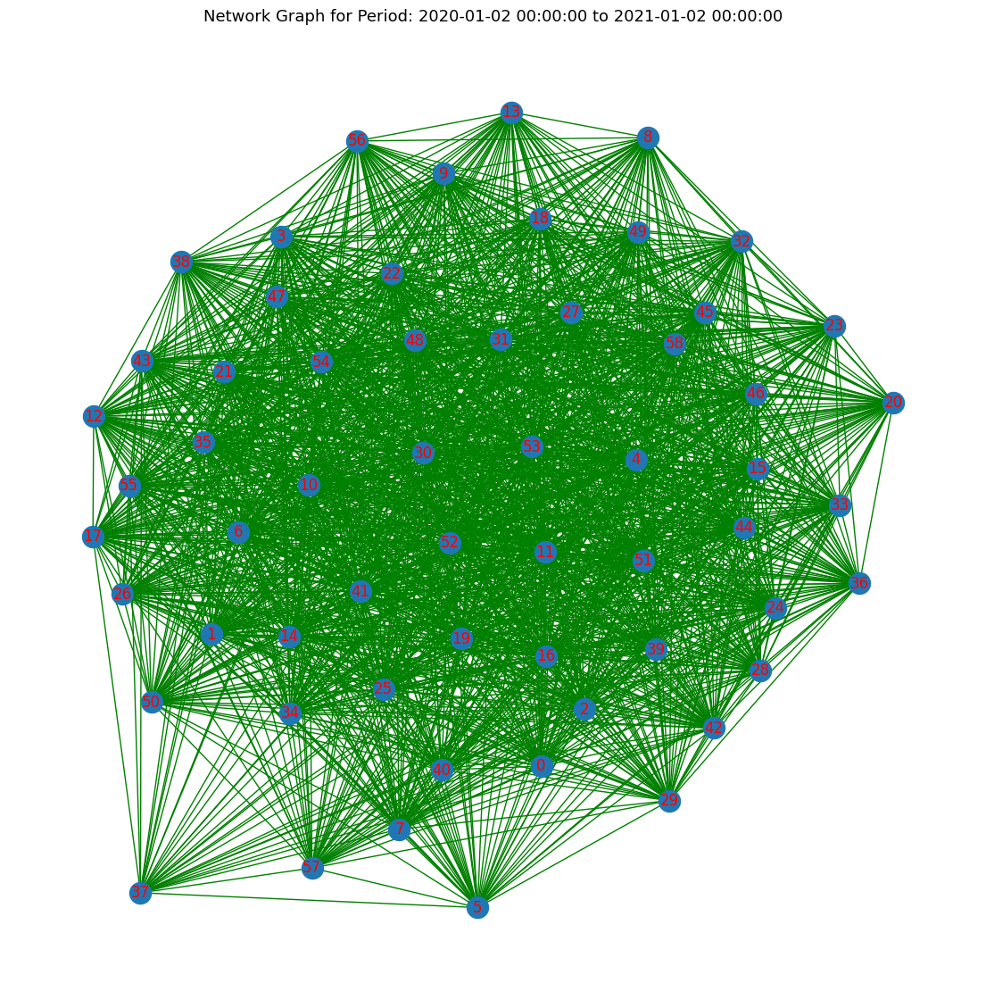

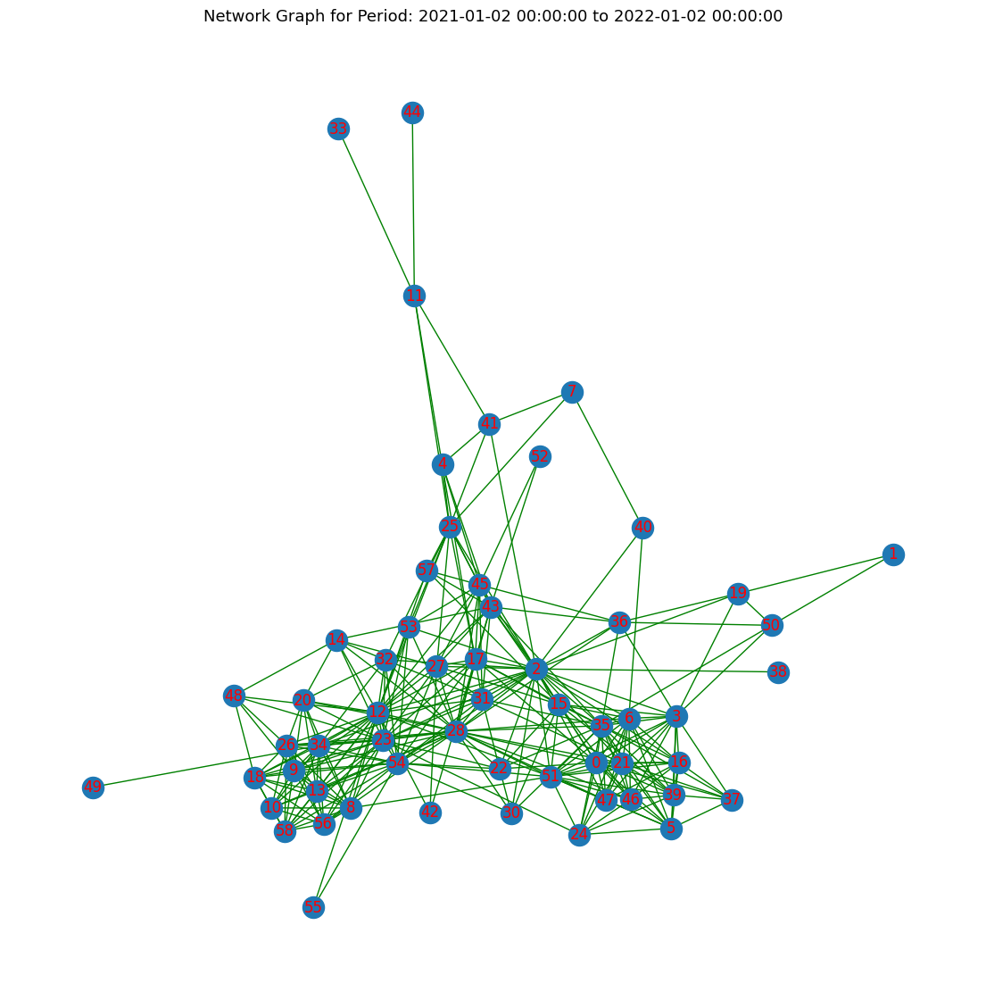

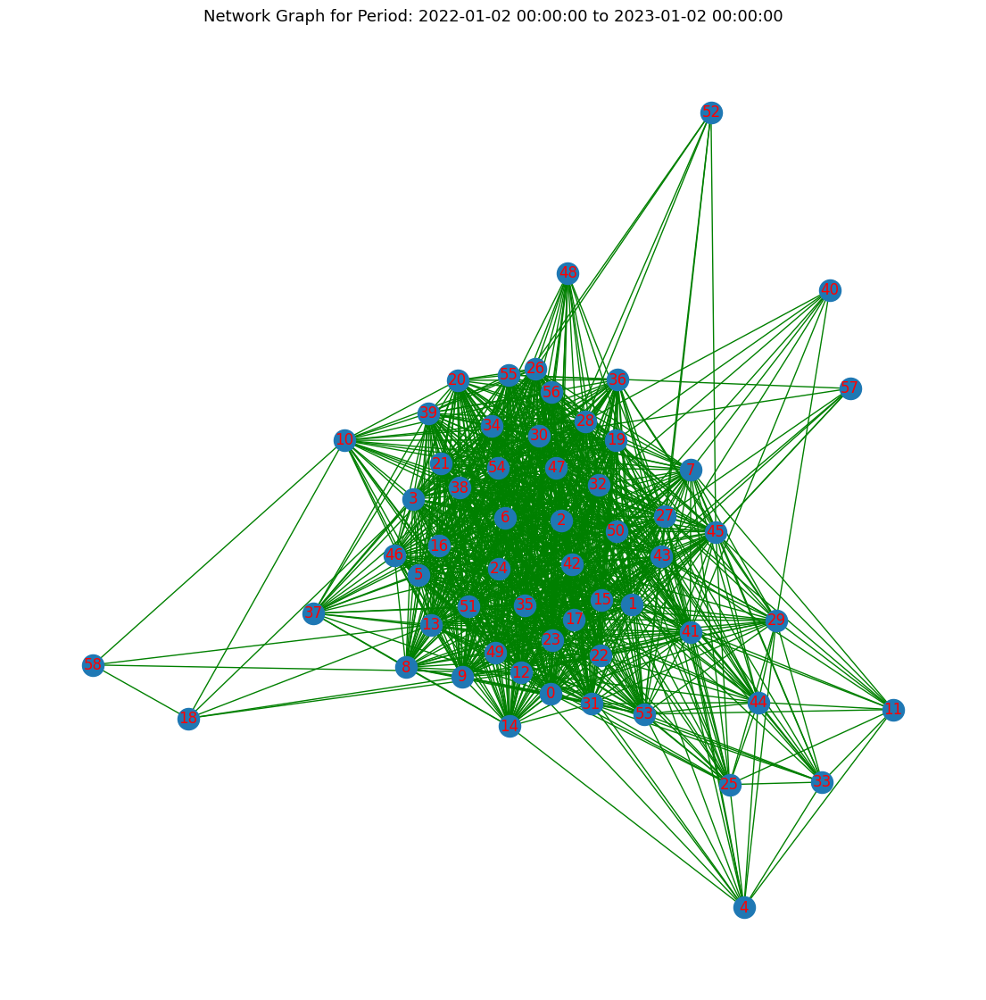

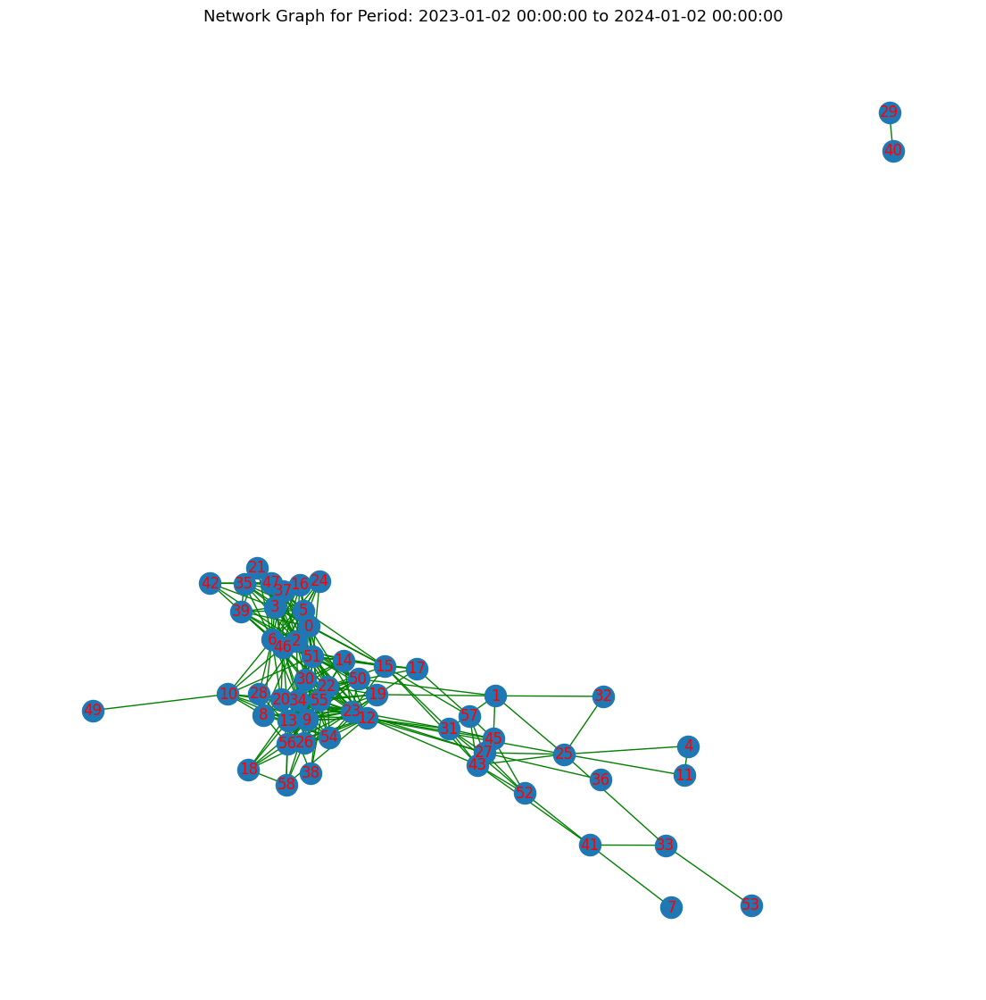

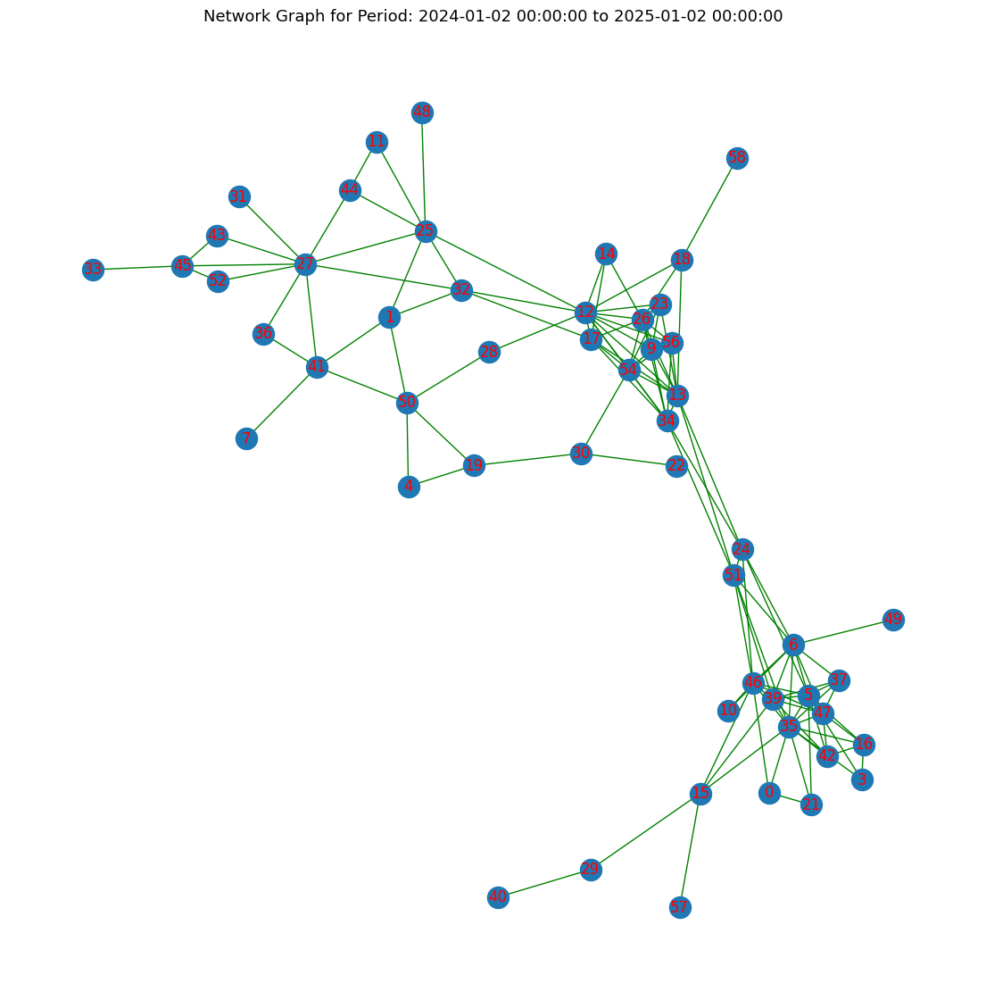

In [ ]:
# for i in range(time_period):

list_corr_US = []
list_density_US = []
list_cluster_US = []
list_path_US = []

for i in range(time_period):
  mask_US = (data3_US.index >= dates[i]) & (data3_US.index < dates[i+1])
  period_data_US = data3_US.loc[mask_US]

  corr_period_matrix_US = period_data_US.corr()
  corr_period_matrix_US = corr_period_matrix_US.to_numpy()
  np.fill_diagonal(corr_period_matrix_US, 0)

  adjacency_matrix_pr_US = corr_period_matrix_US.copy()
  adjacency_matrix_pr_US[adjacency_matrix_pr_US >= threshold_US] = 1
  adjacency_matrix_pr_US[adjacency_matrix_pr_US < threshold_US] = 0

  network_graph_temp = nx.from_numpy_array(np.array(adjacency_matrix_pr_US))
  f = plt.figure(figsize=(14, 14))
  plt.title(f"Network Graph for Period: {dates[i]} to {dates[i+1]}", fontsize=13)
  network_graph_temp.remove_nodes_from(list(nx.isolates(network_graph_temp)))
  nx.draw_spring(network_graph_temp, with_labels=True,font_color='r',edge_color='g')

  avg_corr_pr = np.mean(corr_period_matrix_US)
  ntwk_density_pr = nx.density(network_graph_temp)
  list_corr_US.append(avg_corr_pr)
  list_density_US.append(ntwk_density_pr)

  avg_clustering_pr = nx.average_clustering(network_graph_temp)
  list_cluster_US.append(avg_clustering_pr)

  Gcc_temp = sorted(nx.connected_components(network_graph_temp), key=len, reverse=True)
  G0_temp = network_graph_temp.subgraph(Gcc_temp[0])
  avg_length_pr = nx.average_shortest_path_length(G0_temp)
  list_path_US.append(avg_length_pr)


In [ ]:
x_axis = [date.year for date in dates]
x_axis.pop()
x_axis

[2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021,
 2022,
 2023,
 2024]

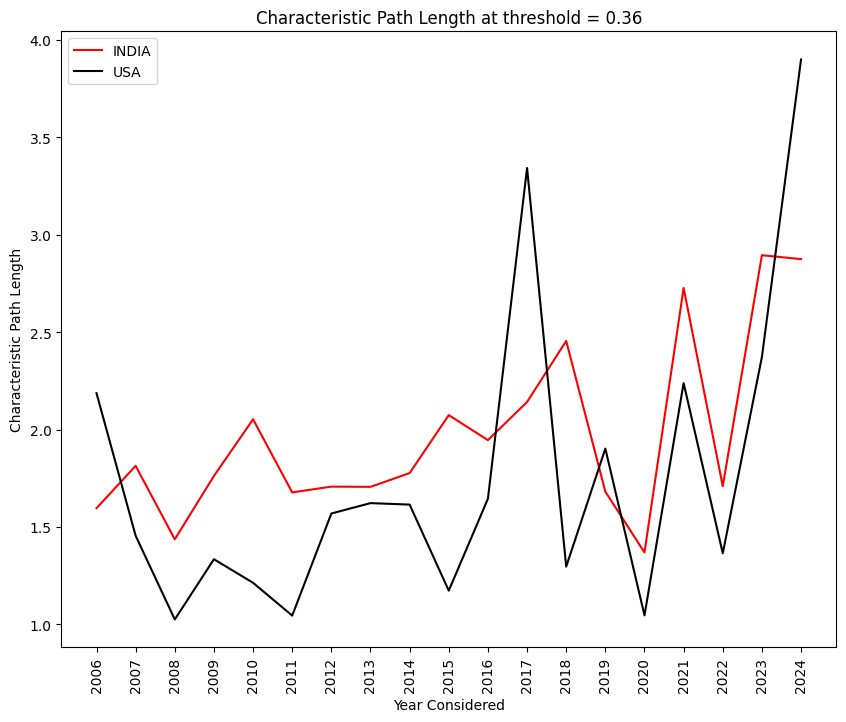

In [ ]:
plt.figure(figsize=(10, 8))
plt.xticks(x_axis)
plt.plot(x_axis, list_path,label="INDIA", color = 'r')
plt.plot(x_axis, list_path_US,label="USA", color='k')
plt.xticks(rotation=90)
plt.xlabel("Year Considered")
plt.ylabel("Characteristic Path Length")
plt.title("Characteristic Path Length at threshold = " + str(threshold))
plt.legend()
plt.show()

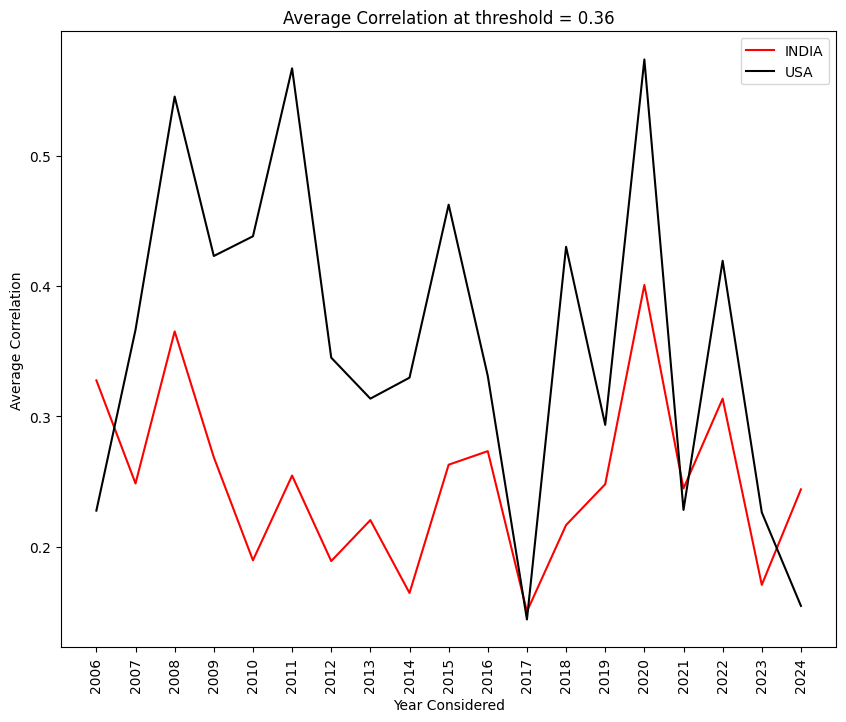

In [ ]:
plt.figure(figsize=(10, 8))
plt.xticks(x_axis)
plt.plot(x_axis, list_corr,label="INDIA", color = 'r')
plt.plot(x_axis, list_corr_US, label="USA", color='k')
plt.xticks(rotation=90)
plt.xlabel("Year Considered")
plt.ylabel("Average Correlation")
plt.title("Average Correlation at threshold = " + str(threshold))
plt.legend()
plt.show()

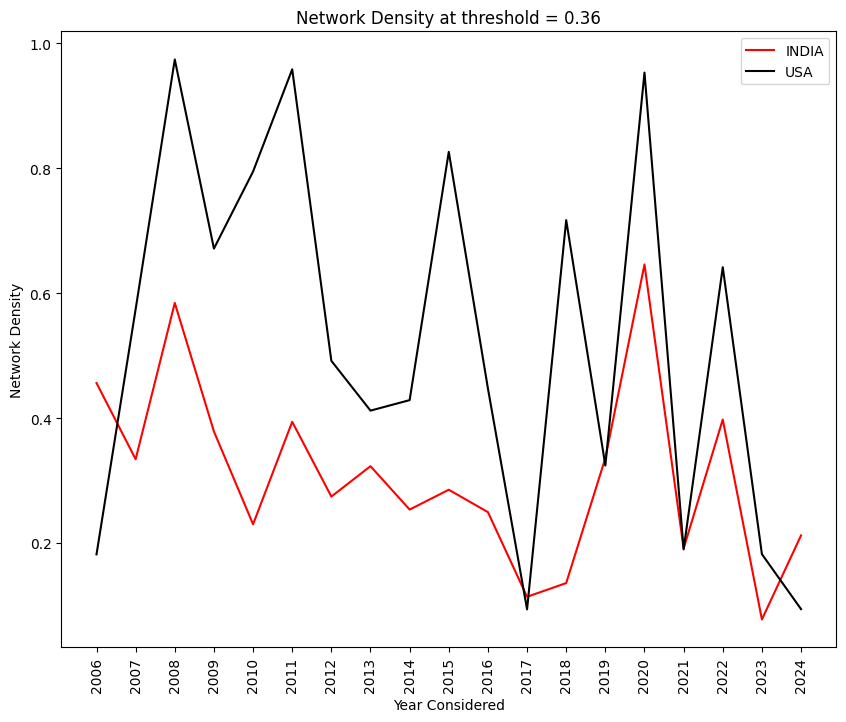

In [ ]:
plt.figure(figsize=(10, 8))
plt.xticks(x_axis)
plt.plot(x_axis, list_density,label="INDIA", color = 'r')
plt.plot(x_axis, list_density_US, label="USA", color='k')
plt.xticks(rotation=90)
plt.xlabel("Year Considered")
plt.ylabel("Network Density")
plt.title("Network Density at threshold = " + str(threshold))
plt.legend()
plt.show()

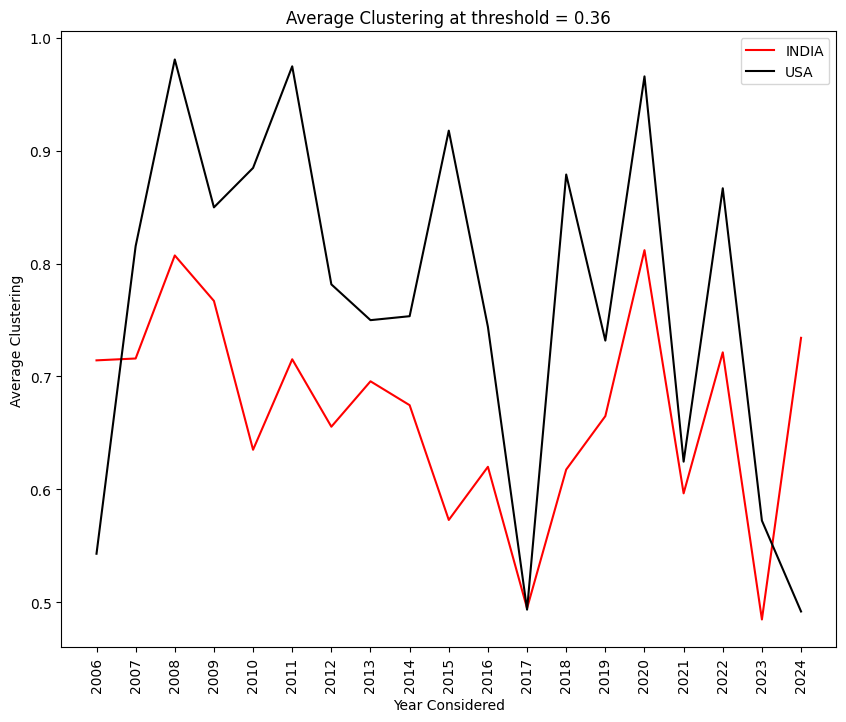

In [ ]:
plt.figure(figsize=(10, 8))
plt.xticks(x_axis)
plt.plot(x_axis, list_cluster,label="INDIA", color = 'r')
plt.plot(x_axis, list_cluster_US, label="USA", color='k')
plt.xticks(rotation=90)
plt.xlabel("Year Considered")
plt.ylabel("Average Clustering")
plt.title("Average Clustering at threshold = " + str(threshold))
plt.legend()
plt.show()

In [ ]:
dates

[datetime.datetime(2006, 1, 2, 0, 0),
 datetime.datetime(2007, 1, 2, 0, 0),
 datetime.datetime(2008, 1, 2, 0, 0),
 datetime.datetime(2009, 1, 2, 0, 0),
 datetime.datetime(2010, 1, 2, 0, 0),
 datetime.datetime(2011, 1, 2, 0, 0),
 datetime.datetime(2012, 1, 2, 0, 0),
 datetime.datetime(2013, 1, 2, 0, 0),
 datetime.datetime(2014, 1, 2, 0, 0),
 datetime.datetime(2015, 1, 2, 0, 0),
 datetime.datetime(2016, 1, 2, 0, 0),
 datetime.datetime(2017, 1, 2, 0, 0),
 datetime.datetime(2018, 1, 2, 0, 0),
 datetime.datetime(2019, 1, 2, 0, 0),
 datetime.datetime(2020, 1, 2, 0, 0),
 datetime.datetime(2021, 1, 2, 0, 0),
 datetime.datetime(2022, 1, 2, 0, 0),
 datetime.datetime(2023, 1, 2, 0, 0),
 datetime.datetime(2024, 1, 2, 0, 0),
 datetime.datetime(2025, 1, 2, 0, 0)]

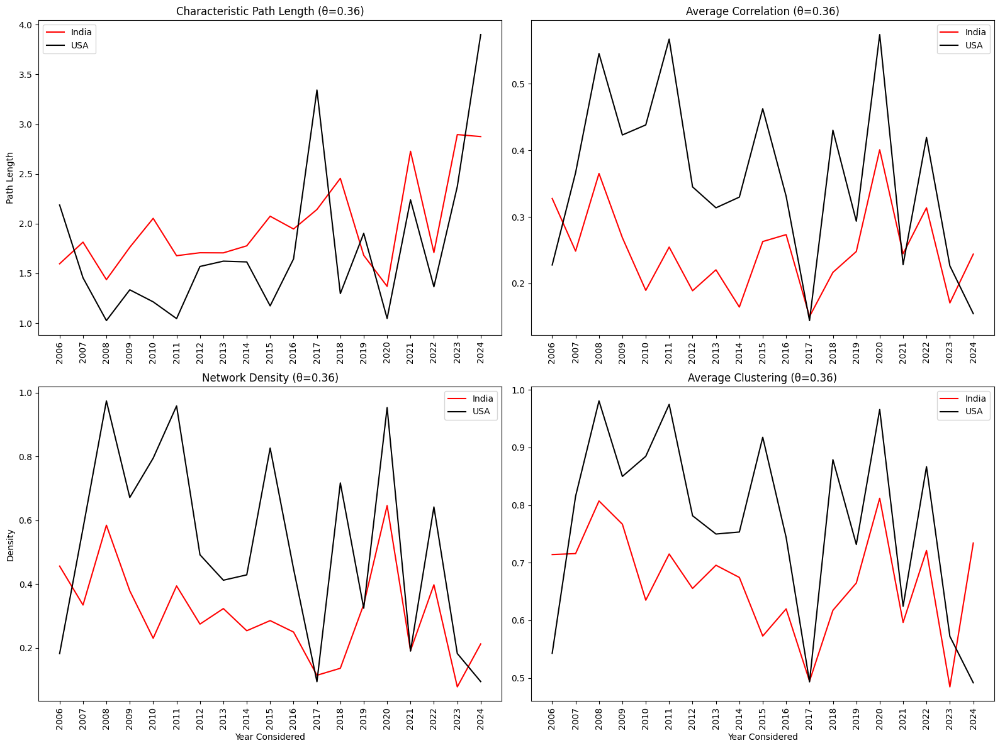

In [ ]:
plt.figure(figsize=(16, 12))

# 1) Characteristic Path Length
plt.subplot(2, 2, 1)
plt.plot(x_axis, list_path, label="India", color='r')
plt.plot(x_axis, list_path_US, label="USA", color='k')
plt.title(f"Characteristic Path Length (θ={threshold})")
plt.ylabel("Path Length")
plt.legend()

# 2) Average Correlation
plt.subplot(2, 2, 2)
plt.plot(x_axis, list_corr, label="India", color='r')
plt.plot(x_axis, list_corr_US, label="USA", color='k')
plt.title(f"Average Correlation (θ={threshold})")
plt.legend()

# 3) Network Density
plt.subplot(2, 2, 3)
plt.plot(x_axis, list_density, label="India", color='r')
plt.plot(x_axis, list_density_US, label="USA", color='k')
plt.title(f"Network Density (θ={threshold})")
plt.xlabel("Year Considered")
plt.ylabel("Density")
plt.legend()

# 4) Average Clustering
plt.subplot(2, 2, 4)
plt.plot(x_axis, list_cluster, label="India", color='r')
plt.plot(x_axis, list_cluster_US, label="USA", color='k')
plt.title(f"Average Clustering (θ={threshold})")
plt.xlabel("Year Considered")
plt.legend()

# Rotate x-axis labels for readability
for i in range(1, 5):
    ax = plt.subplot(2, 2, i)
    ax.set_xticks(x_axis)
    ax.set_xticklabels(x_axis, rotation=90)

plt.tight_layout()
plt.show()